In [1]:
import os
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"

# os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform" 
# This makes JAX allocate exactly what is needed on demand, and deallocate memory that is no longer needed (note that this is the only configuration that will deallocate GPU memory, instead of reusing it). This is very slow, so is not recommended for general use, but may be useful for running with the minimal possible GPU memory footprint or debugging OOM failures.

os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".95"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import jax
import jax.numpy as jnp
from jax import random
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt
from flax import linen as nn
import optax
import jax
import jax.numpy as jnp
from jax import random, jit
import optax
from tqdm import tqdm
import matplotlib.pyplot as plt
import wandb
from src.models import ResNet
import pandas as pd
import seaborn as sns
plt.rcParams['figure.figsize'] = (4, 3)
# sns.set_context("notebook")
# sns.set_style("white")
# sns.set_theme(rc={'figure.figsize': (4, 3)})

%load_ext autoreload
%autoreload 2

# %env XLA_FLAGS="--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = ('--xla_force_host_platform_device_count=10 '
#                            '--xla_dump_to=xla_dump/')
%env XLA_FLAGS

#jax.devices("gpu")

'--xla_force_host_platform_device_count=10'

### Cifar analyse

In [57]:
api = wandb.Api()
results = []
# for s_id in ['vl6382k1', 'x26ip745', 'd8bi25u9']:
for s_id in ['b4iwxik8',]:
    t_bar = tqdm(api.sweep(f"ddold/cifar_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       Seed=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       acc_test_curve=run.summary.get('acc_test_curve', np.nan),
                       acc_test_curve_last=run.summary.get('acc_test_curve_last', np.nan),
                       acc_val_curve=run.summary.get('acc_val_curve', np.nan),
                       acc_val_curve_last=run.summary.get('acc_val_curve_last', np.nan),
                       nll_test_curve=run.summary.get('nll_test_curve', np.nan),
                       nll_test_curve_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val_curve=run.summary.get('nll_val_curve', np.nan),
                       nll_val_curve_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df = pd.DataFrame(results)
df

Sweep id: b4iwxik8:  18%|█▊        | 51/288 [00:00<00:00, 449.56it/s, elated-sweep-194]   

Encoundert problem with run icy-sweep-270; state: crashed


Sweep id: b4iwxik8:  64%|██████▎   | 183/288 [00:00<00:00, 408.64it/s, cosmic-sweep-89]    

Encoundert problem with run solar-sweep-175; state: crashed


Sweep id: b4iwxik8: 100%|██████████| 288/288 [00:00<00:00, 422.18it/s, graceful-sweep-1]      

Encoundert problem with run eager-sweep-78; state: crashed
Encoundert problem with run ethereal-sweep-72; state: crashed


,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last
0,vy63939m,10,1,1.000000e-08,0.01,0.0010,False,200,0.005,0.927600,0.389928,1.00000,0.38310,0.311713,4.774229,0.001880,4.742199,0.039911,11.682710
1,pfsvqzd0,10,0,1.000000e-08,0.01,0.0010,False,200,0.005,0.927578,0.372370,0.93784,0.37278,0.311766,11.776340,0.234382,11.638179,0.039818,11.753841
2,kwwjp04t,10,1,1.000000e-08,0.01,0.0001,False,200,0.005,0.927606,0.391092,1.00000,0.39156,0.311740,24.841276,0.001881,25.054377,0.039911,100.147018
3,hrai84d4,10,0,1.000000e-08,0.01,0.0001,False,200,0.005,0.927536,0.437032,0.93798,0.43494,0.311794,24.182154,0.234435,23.975790,0.039818,99.804787
4,l96twiq1,10,1,1.000000e-08,0.01,0.0000,False,200,0.005,0.927610,0.417532,1.00000,0.42086,0.311743,28.634001,0.001881,28.033852,0.039911,274.767517
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279,v12wktbb,2,1,1.000000e-06,0.00,0.0000,False,200,0.050,0.927828,0.866854,1.00000,0.90588,0.312160,0.885968,0.001888,0.609586,0.050713,45.974533
280,tw3u1uty,2,1,1.000000e-06,0.00,0.0010,True,200,0.050,0.927972,0.397132,1.00000,0.40402,0.311975,3.508064,0.001890,3.452630,0.050712,9.365849
281,9i6mcej8,2,0,1.000000e-06,0.00,0.0000,False,200,0.050,0.927570,0.876264,0.93702,0.87636,0.310427,0.776735,0.232255,0.760146,0.013152,45.815037
282,n5qxk763,2,1,1.000000e-06,0.00,0.0001,True,200,0.050,0.927820,0.726372,1.00000,0.72248,0.312122,1.012525,0.001887,1.012875,0.050712,20.937195


In [58]:
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan]

,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last


In [59]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and (c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")

Unique configuartions: 
SubspaceDim [10  2]
Seed [1 0]
Jitter [1.e-08 1.e-06]
Gravity [0.01   0.0001 0.    ]
WeightDecay [0.001  0.0001 0.    ]
RemoveInitialPermutation [False  True]
Epochs [200]
Lr [0.005 0.05 ]

Experiment differs in ['SubspaceDim', 'Jitter', 'Gravity', 'WeightDecay', 'RemoveInitialPermutation', 'Lr'] configs


In [60]:
variable_idx

['SubspaceDim',
 'Jitter',
 'Gravity',
 'WeightDecay',
 'RemoveInitialPermutation',
 'Lr']

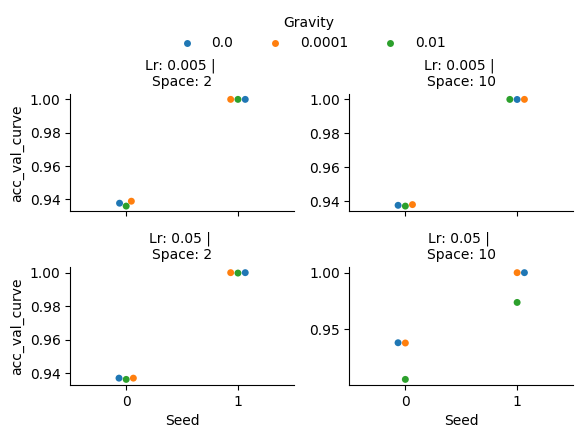

In [ ]:
from matplotlib import colors
import seaborn as sns
# Seed 1 is has false dataset split

df_subset = df_clean[(df_clean['RemoveInitialPermutation'] == False) & (df_clean['Jitter'] == 1.e-06) & (df_clean['WeightDecay'] == 0.0) ]

g = sns.catplot(data=df_subset, y='acc_val_curve', x='Seed',
                col='SubspaceDim', row='Lr', kind='swarm', hue='Gravity', sharey=False, height=2, aspect=1.5, palette='tab10',) 
                #hue_norm=norm)
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.1), ncols=6)

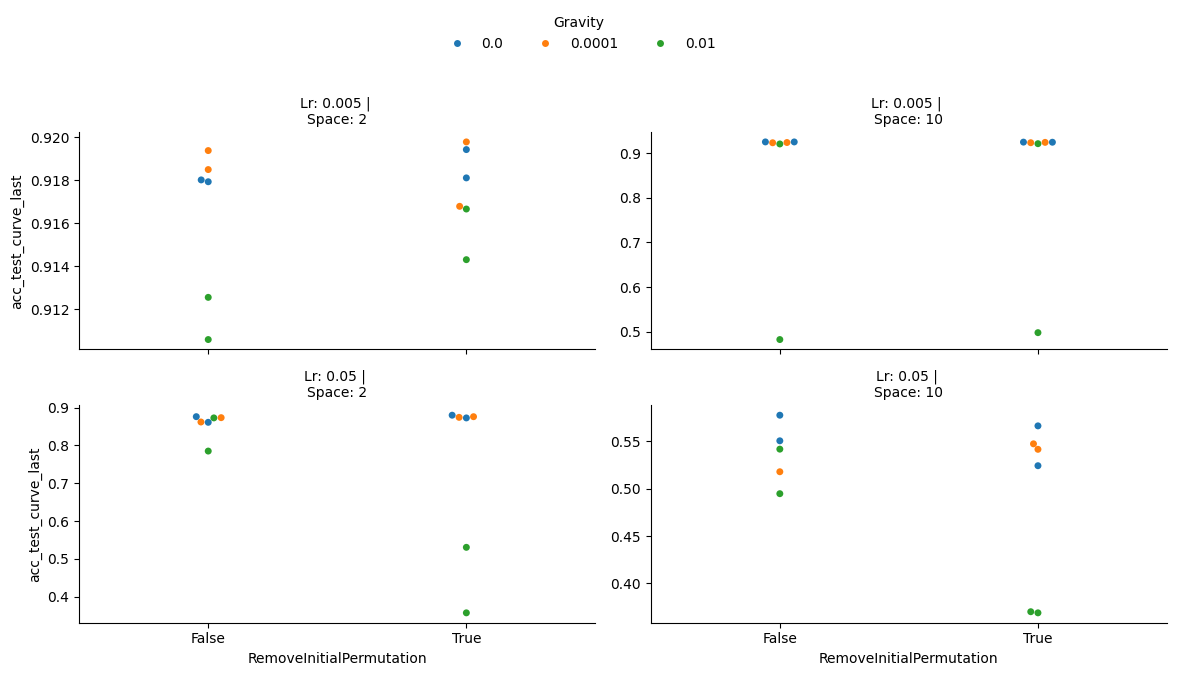

In [ ]:
from matplotlib import colors
import seaborn as sns

# Remove permutation doesnet increase performance

df_subset = df_clean[ (df_clean['WeightDecay'] == 0.) & (df_clean['Seed'] == 0) & (df_clean['Jitter'] == 1e-8)]
df_subset = df_clean[ (df_clean['WeightDecay'] == 0.) & (df_clean['Seed'] == 0)]

g = sns.catplot(data=df_subset, y='acc_test_curve_last', x='RemoveInitialPermutation',
                col='SubspaceDim', row='Lr', kind='swarm', hue='Gravity', sharey=False, height=2, aspect=1.5, palette='tab10',) 
                #hue_norm=norm)
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)

/tmp/ipykernel_152682/2715075359.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity' 'Jitter' 'RemoveInitialPermutation' 'WeightDecay']


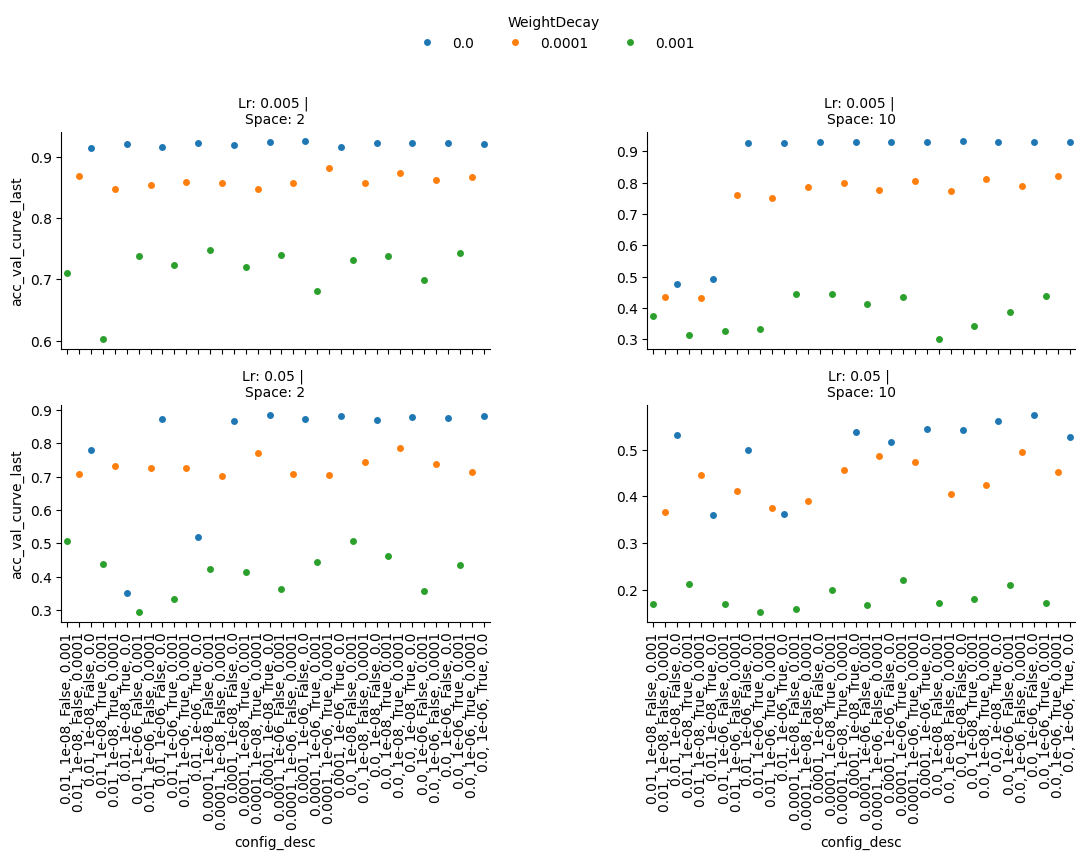

In [ ]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[(df_clean['Seed'] == 0)]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='acc_val_curve_last', x='config_desc',
                col='SubspaceDim', row='Lr', kind='swarm', hue='WeightDecay', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

In [ ]:
df_subset[desc_cols[::1]].astype(str).agg(', '.join, axis=1)
df_subset_sorted = df_subset.sort_values(by=desc_cols)
df_subset_sorted

,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last,config_desc
195,a6sgab0q,10,0,1.000000e-08,0.0000,0.000,False,200,0.005,0.927952,0.925598,0.93754,0.93126,0.309753,0.349783,0.234600,0.290678,0.113839,3.950859,"1e-08, False, 0.0, 0.0"
207,h967vxaj,10,0,1.000000e-08,0.0000,0.000,False,200,0.050,0.927588,0.550356,0.93800,0.54228,0.311681,11.312123,0.234240,11.410514,0.010684,72.378151,"1e-08, False, 0.0, 0.0"
217,0xx0wvj0,2,0,1.000000e-08,0.0000,0.000,False,200,0.005,0.926956,0.918022,0.93768,0.92240,0.310613,0.427287,0.231933,0.356905,0.122088,4.819927,"1e-08, False, 0.0, 0.0"
229,2gmj5eng,2,0,1.000000e-08,0.0000,0.000,False,200,0.050,0.927568,0.861302,0.93702,0.86854,0.310435,0.976824,0.232251,0.941328,0.013107,45.841499,"1e-08, False, 0.0, 0.0"
100,mgjnd5nb,10,0,1.000000e-08,0.0001,0.000,False,200,0.005,0.927552,0.923696,0.93800,0.92956,0.311798,0.360554,0.234407,0.295395,0.001235,7.382473,"1e-08, False, 0.0, 0.0001"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186,pzc60p09,2,0,1.000000e-06,0.0001,0.001,True,200,0.050,0.927586,0.434208,0.93704,0.44284,0.310195,2.524013,0.231792,2.537070,0.046706,9.472963,"1e-06, True, 0.001, 0.0001"
54,2dzn2ovr,10,0,1.000000e-06,0.0100,0.001,True,200,0.005,0.922238,0.327380,0.93262,0.33260,0.241525,3.764883,0.206227,3.787294,14.392229,11.624568,"1e-06, True, 0.001, 0.01"
66,pu3e9a4d,10,0,1.000000e-06,0.0100,0.001,True,200,0.050,0.895018,0.149784,0.90334,0.15136,0.442034,122.348083,0.371694,124.118134,35.532448,15.743130,"1e-06, True, 0.001, 0.01"
78,am1bfk1u,2,0,1.000000e-06,0.0100,0.001,True,200,0.005,0.923164,0.726660,0.93182,0.72274,0.248631,0.906966,0.207947,0.927875,3.212644,6.034583,"1e-06, True, 0.001, 0.01"


/tmp/ipykernel_152682/2897130361.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']


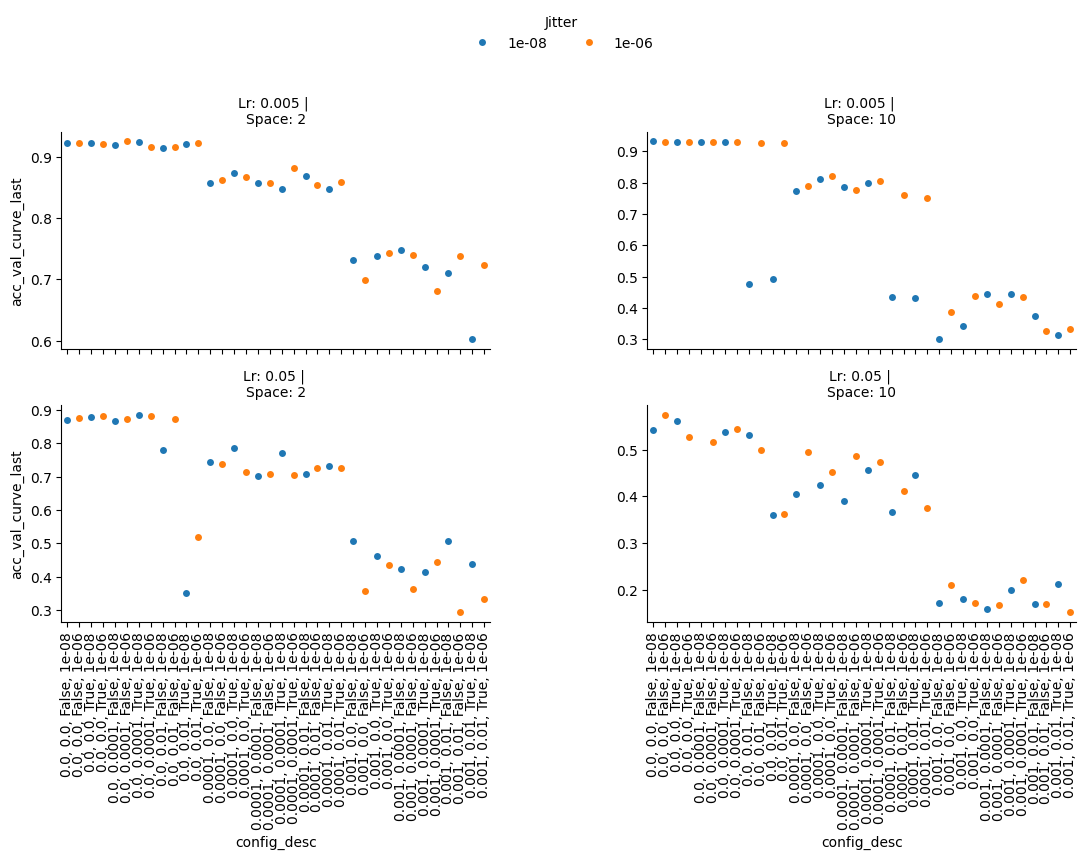

In [ ]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[(df_clean['Seed'] == 0)]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
desc_cols = ['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)
df_subset_sorted = df_subset.sort_values(by=desc_cols)

g = sns.catplot(data=df_subset_sorted, y='acc_val_curve_last', x='config_desc',
                col='SubspaceDim', row='Lr', kind='swarm', hue='Jitter', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

conclusion =>

weight_decay = 0  => increased performs



/tmp/ipykernel_152682/971385804.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']


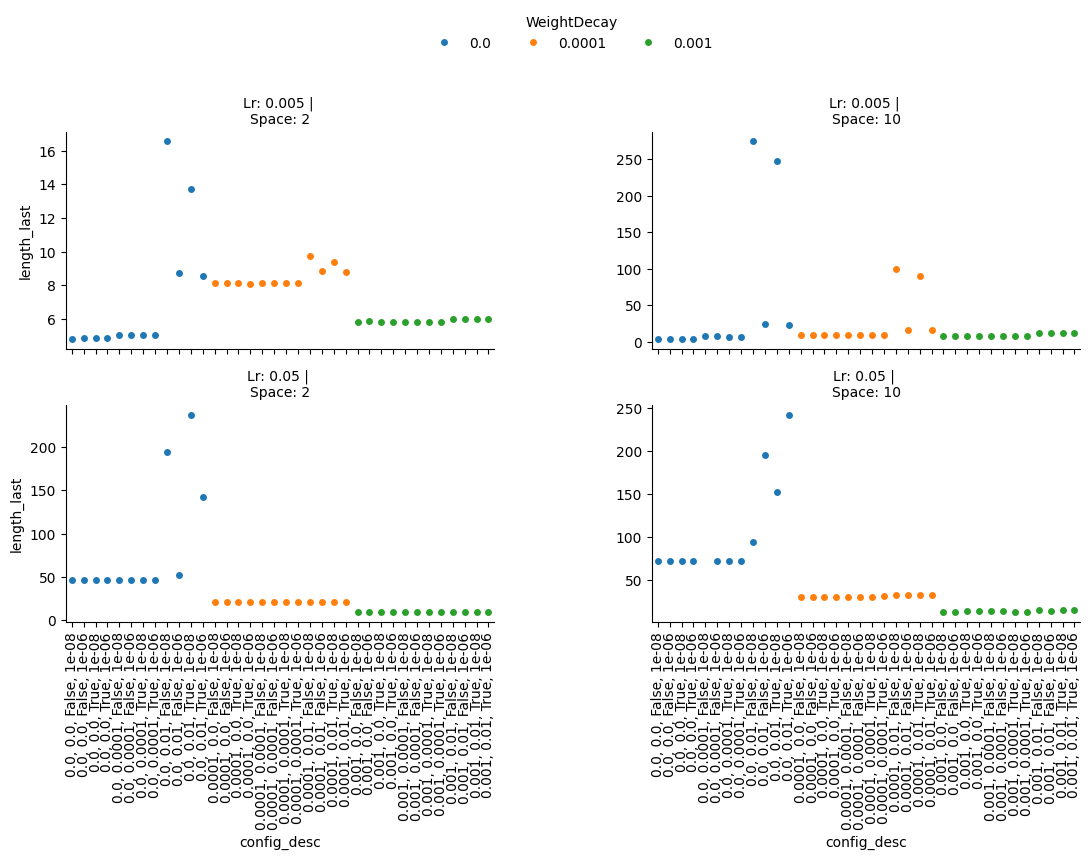

In [ ]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[(df_clean['Seed'] == 0)]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
desc_cols = ['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)
df_subset_sorted = df_subset.sort_values(by=desc_cols)

g = sns.catplot(data=df_subset_sorted, y='length_last', x='config_desc',
                col='SubspaceDim', row='Lr', kind='swarm', hue='WeightDecay', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)

# g.set(ylim=(0, 1))

# # Add second y-axis for acc_val_curve_last
# for ax, (_, sub_df) in zip(g.axes.flatten(), df_subset_sorted.groupby(['SubspaceDim', 'Lr'])):
#     ax2 = ax.twinx()
#     # Get x positions for each config_desc
#     x_ticks = range(len(sub_df['config_desc']))
#     acc_vals = sub_df['acc_val_curve_last']
#     ax2.plot(x_ticks, acc_vals, 'ro', label='acc_val_curve_last')
#     ax2.set_ylabel('acc_val_curve_last', color='r')
#     ax2.tick_params(axis='y', labelcolor='r')
#     ax2.set_ylim(0, 1)

for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

#### with energy and new metrics 

In [63]:
api = wandb.Api()
results = []
# for s_id in ['vl6382k1', 'x26ip745', 'd8bi25u9']:
for s_id in ['fyeiomj4',]:
    t_bar = tqdm(api.sweep(f"ddold/cifar_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       Seed=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       EnergyWeakening=run.config['curve_params']['energy_weakening'],
                       acc_test_curve=run.summary.get('acc_test_curve', np.nan),
                       acc_test_curve_last=run.summary.get('acc_test_curve_last', np.nan),
                       acc_val_curve=run.summary.get('acc_val_curve', np.nan),
                       acc_val_curve_last=run.summary.get('acc_val_curve_last', np.nan),
                       nll_test_curve=run.summary.get('nll_test_curve', np.nan),
                       nll_test_curve_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val_curve=run.summary.get('nll_val_curve', np.nan),
                       nll_val_curve_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df = pd.DataFrame(results)
df

Sweep id: fyeiomj4:   0%|          | 0/288 [00:00<?, ?it/s, trim-sweep-269]    

Sweep id: fyeiomj4: 100%|██████████| 288/288 [00:00<00:00, 411.74it/s, spring-sweep-1]        


,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last
0,r8m00b19,20,4,1.000000e-08,0.1,0,False,200,0.005,0.1,0.927600,0.100000,0.93800,0.09500,0.311786,NaN,0.234462,NaN,0.000024,NaN
1,hr472k3n,20,3,1.000000e-08,0.1,0,False,200,0.005,0.1,0.927600,0.100220,0.93800,0.09938,0.311785,1.191671e+10,0.234466,1.210064e+10,0.000024,14396.045898
2,5gfqqydp,20,1,1.000000e-08,0.1,0,False,200,0.005,0.1,0.927600,0.100000,0.93800,0.09500,0.311785,NaN,0.234466,NaN,0.000024,NaN
3,vk9b900a,20,0,1.000000e-08,0.1,0,False,200,0.005,0.1,0.927600,0.097458,0.93800,0.10068,0.311785,2.253048e+07,0.234463,2.125983e+07,0.000024,13895.279297
4,hjdiq23m,20,4,1.000000e-08,0.1,0,False,200,0.050,0.1,0.927600,0.100000,0.93800,0.09500,0.311786,NaN,0.234462,NaN,0.000024,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,9w4a5d47,2,0,1.000000e-08,0.0,0,False,200,0.005,10.0,0.928150,0.927788,0.93768,0.93356,0.309967,3.509504e-01,0.232353,2.738832e-01,0.058727,1.168407
284,empihtod,2,4,1.000000e-08,0.0,0,False,200,0.050,10.0,0.927676,0.870472,0.93702,0.88044,0.310848,8.997313e-01,0.232654,8.140486e-01,0.004011,30.121128
285,5n49bx48,2,3,1.000000e-08,0.0,0,False,200,0.050,10.0,0.927606,0.873892,0.93702,0.87702,0.311480,7.721348e-01,0.232358,7.152387e-01,0.022641,30.151690
286,8fxiarns,2,1,1.000000e-08,0.0,0,False,200,0.050,10.0,0.923422,0.881372,0.93716,0.88614,0.320940,7.998755e-01,0.233424,7.784144e-01,0.327173,29.971779


In [64]:

idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan]

,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last
0,r8m00b19,20,4,1.000000e-08,0.10,0,False,200,0.005,0.1,0.927600,0.1,0.93800,0.095,3.117858e-01,NaN,2.344622e-01,NaN,0.000024,NaN
2,5gfqqydp,20,1,1.000000e-08,0.10,0,False,200,0.005,0.1,0.927600,0.1,0.93800,0.095,3.117850e-01,NaN,2.344659e-01,NaN,0.000024,NaN
4,hjdiq23m,20,4,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117858e-01,NaN,2.344622e-01,NaN,0.000024,NaN
5,plz6rxo5,20,3,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117854e-01,NaN,2.344662e-01,NaN,0.000024,NaN
6,66k9j3rs,20,1,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117850e-01,NaN,2.344659e-01,NaN,0.000024,NaN
7,50vgp877,20,0,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117847e-01,NaN,2.344631e-01,NaN,0.000024,NaN
12,timu5z88,10,4,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117858e-01,NaN,2.344636e-01,NaN,0.000019,NaN
13,ryznw351,10,1,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117868e-01,NaN,2.344656e-01,NaN,0.000019,NaN
14,3btex836,10,3,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117860e-01,NaN,2.344641e-01,NaN,0.000019,NaN
15,mslg7d4k,10,0,1.000000e-08,0.10,0,False,200,0.050,0.1,0.927600,0.1,0.93800,0.095,3.117852e-01,NaN,2.344664e-01,NaN,0.000019,NaN


In [65]:
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
print("Runs with problems: ", df[idx_config_with_nan])

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)

print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and (c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
variable_idx

Runs with problems:            Id  SubspaceDim  Seed        Jitter  Gravity  WeightDecay  \
0   r8m00b19           20     4  1.000000e-08     0.10            0   
2   5gfqqydp           20     1  1.000000e-08     0.10            0   
4   hjdiq23m           20     4  1.000000e-08     0.10            0   
5   plz6rxo5           20     3  1.000000e-08     0.10            0   
6   66k9j3rs           20     1  1.000000e-08     0.10            0   
7   50vgp877           20     0  1.000000e-08     0.10            0   
12  timu5z88           10     4  1.000000e-08     0.10            0   
13  ryznw351           10     1  1.000000e-08     0.10            0   
14  3btex836           10     3  1.000000e-08     0.10            0   
15  mslg7d4k           10     0  1.000000e-08     0.10            0   
20  trkfasxa            5     4  1.000000e-08     0.10            0   
21  gmg8gjsq            5     3  1.000000e-08     0.10            0   
22  0ubzpptm            5     1  1.000000e-08     0.10  

['SubspaceDim', 'Gravity', 'Lr', 'EnergyWeakening']

['EnergyWeakening' 'Gravity']


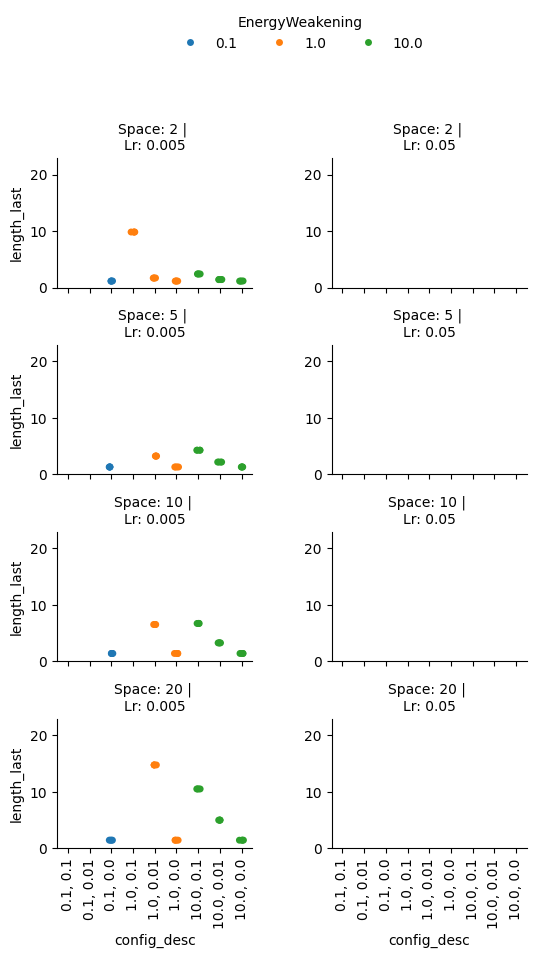

In [73]:
# small energy weakening does not work
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='length_last', x='config_desc',
                row='SubspaceDim', col='Lr', kind='strip', hue='EnergyWeakening', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nLr: {col_name}')
g.tight_layout()
g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

['EnergyWeakening' 'Gravity']


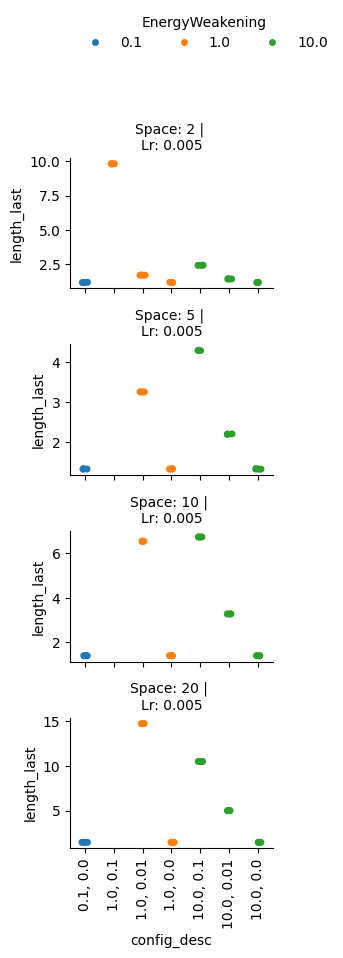

In [74]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[df_clean['acc_val_curve_last'] >= 0.9]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
df_subset.loc[:, 'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='length_last', x='config_desc',
                row='SubspaceDim', col='Lr', kind='strip', hue='EnergyWeakening', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nLr: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

['EnergyWeakening' 'Gravity']


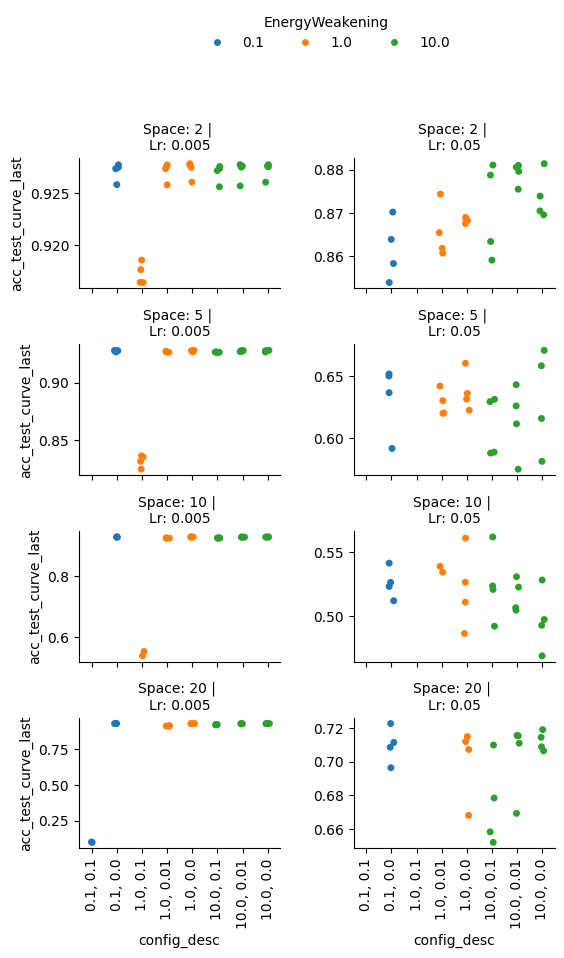

In [71]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[df_clean['acc_val_curve'] >= 0.9]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='acc_test_curve_last', x='config_desc',
                row='SubspaceDim', col='Lr', kind='strip', hue='EnergyWeakening', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nLr: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

#### Point to Curve training with entropy

In [136]:
api = wandb.Api()
results = []
# for s_id in ['vl6382k1', 'x26ip745', 'd8bi25u9']:
for s_id in ['mp9zwu18',]:
    t_bar = tqdm(api.sweep(f"ddold/cifar_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       Seed=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       EnergyWeakening=run.config['curve_params']['energy_weakening'],
                       Regularizer=run.config['curve_params']['regularizer'],
                       acc_test_curve=run.summary.get('acc_test_curve', np.nan),
                       acc_test_curve_last=run.summary.get('acc_test_curve_last', np.nan),
                       acc_val_curve=run.summary.get('acc_val_curve', np.nan),
                       acc_val_curve_last=run.summary.get('acc_val_curve_last', np.nan),
                       nll_test_curve=run.summary.get('nll_test_curve', np.nan),
                       nll_test_curve_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val_curve=run.summary.get('nll_val_curve', np.nan),
                       nll_val_curve_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),
                       # new
                       entropy_test_curve=run.summary.get('entropy_test_curve', np.nan),
                       entropy_test_curve_last=run.summary.get('entropy_test_curve_last', np.nan),
                       entropy_val_curve=run.summary.get('entropy_val_curve', np.nan),
                       entropy_val_curve_last=run.summary.get('entropy_val_curve_last', np.nan),
                       cosine_similarity=run.summary.get('summed_cosine_similarity', np.nan),
                       init_test_acc=run.summary.get('init_test_acc', np.nan),
                       init_test_loss=run.summary.get('init_test_loss', np.nan),
                       init_valid_acc=run.summary.get('init_valid_acc', np.nan),
                       init_valid_loss=run.summary.get('init_valid_loss', np.nan),
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df = pd.DataFrame(results)
df.head()

Sweep id: mp9zwu18: 100%|██████████| 48/48 [00:00<00:00, 573.75it/s, dandy-sweep-6]


,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,length_last,entropy_test_curve,entropy_test_curve_last,entropy_val_curve,entropy_val_curve_last,cosine_similarity,init_test_acc,init_test_loss,init_valid_acc,init_valid_loss
0,7d2xqqji,2,1,1.000000e-08,0.010,0,False,200,0.005,1,...,1.186153,0.082866,0.067524,0.082958,0.070527,2.998972,0.9276,0.311945,0.938,0.234592
1,epu1d2bj,2,0,1.000000e-08,0.010,0,False,200,0.005,1,...,1.207305,0.082397,0.066707,0.081334,0.072346,2.998935,0.9276,0.311945,0.938,0.234592
2,w1kqqobq,10,0,1.000000e-08,0.001,0,False,200,0.005,1,...,1.428024,0.082269,0.075343,0.081978,0.079278,54.995121,0.9276,0.311945,0.938,0.234592
3,baln236o,2,4,1.000000e-08,0.001,0,False,200,0.005,1,...,1.150738,0.082849,0.067028,0.083124,0.069764,2.999033,0.9276,0.311945,0.938,0.234592
4,3gbyisl7,2,3,1.000000e-08,0.001,0,False,200,0.005,1,...,1.152283,0.082246,0.067089,0.082091,0.072924,2.999029,0.9276,0.311945,0.938,0.234592


In [139]:
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
print("Runs with problems: ", df[idx_config_with_nan])

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)

print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and (c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
variable_idx

Runs with problems:            Id  SubspaceDim  Seed        Jitter  Gravity  WeightDecay  \
7   zlfp8kql           20     4  1.000000e-08      1.0            0   
8   0ifbdvw2           20     3  1.000000e-08      1.0            0   
9   mgxyk3wb           20     1  1.000000e-08      1.0            0   
10  rihkyhxk           20     0  1.000000e-08      1.0            0   
11  ru810tt5           10     4  1.000000e-08      1.0            0   
12  3gnve79z           10     3  1.000000e-08      1.0            0   
13  aicmpi7n           10     1  1.000000e-08      1.0            0   
14  7xgofem8           10     0  1.000000e-08      1.0            0   
15  j9us90c5            2     4  1.000000e-08      1.0            0   
16  u1jhze4x            2     3  1.000000e-08      1.0            0   
17  arxls5s0            2     1  1.000000e-08      1.0            0   
18  qbm0p0wg            2     0  1.000000e-08      1.0            0   

    RemoveInitialPermutation  Epochs     Lr  EnergyWeak

['SubspaceDim', 'Gravity']

/tmp/ipykernel_775401/2772926291.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity']


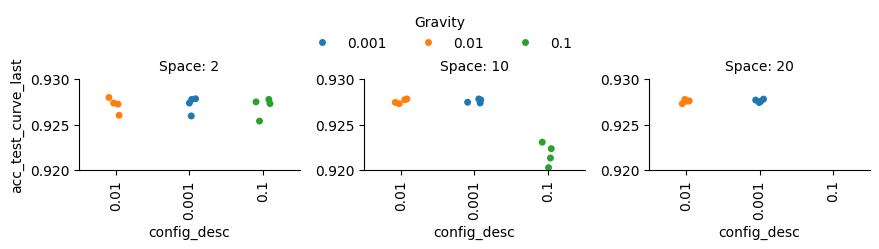

In [140]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim',])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='acc_test_curve_last', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Gravity', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='{row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
# g.set(ylim=(0.31, .36))
g.set(ylim=(0.92, .93))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

['Gravity']


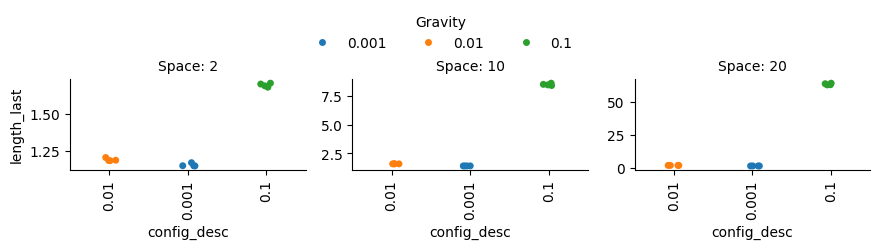

In [141]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim',])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='length_last', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Gravity', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='{row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

['Gravity']


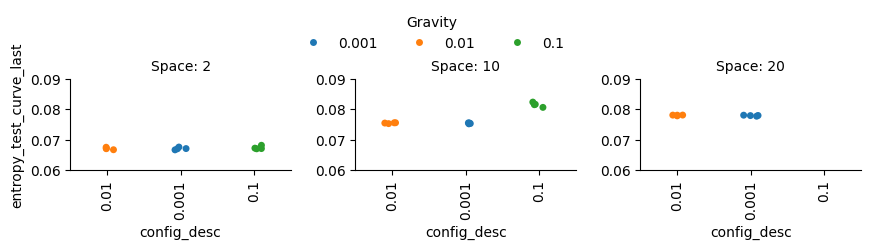

In [142]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim',])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='entropy_test_curve_last', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Gravity', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='{row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()

g.set(ylim=(0.06, .09))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

#### Curve params are only non BatchNorm Layers

In [143]:
api = wandb.Api()
results = []
# for s_id in ['vl6382k1', 'x26ip745', 'd8bi25u9']:
for s_id in ['uf89xmtw',]:
    t_bar = tqdm(api.sweep(f"ddold/cifar_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       Seed=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       EnergyWeakening=run.config['curve_params']['energy_weakening'],
                       Regularizer=run.config['curve_params']['regularizer'],
                       acc_test_curve=run.summary.get('acc_test_curve', np.nan),
                       acc_test_curve_last=run.summary.get('acc_test_curve_last', np.nan),
                       acc_val_curve=run.summary.get('acc_val_curve', np.nan),
                       acc_val_curve_last=run.summary.get('acc_val_curve_last', np.nan),
                       nll_test_curve=run.summary.get('nll_test_curve', np.nan),
                       nll_test_curve_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val_curve=run.summary.get('nll_val_curve', np.nan),
                       nll_val_curve_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),
                       # new
                       entropy_test_curve=run.summary.get('entropy_test_curve', np.nan),
                       entropy_test_curve_last=run.summary.get('entropy_test_curve_last', np.nan),
                       entropy_val_curve=run.summary.get('entropy_val_curve', np.nan),
                       entropy_val_curve_last=run.summary.get('entropy_val_curve_last', np.nan),
                       cosine_similarity=run.summary.get('summed_cosine_similarity', np.nan),
                       init_test_acc=run.summary.get('init_test_acc', np.nan),
                       init_test_loss=run.summary.get('init_test_loss', np.nan),
                       init_valid_acc=run.summary.get('init_valid_acc', np.nan),
                       init_valid_loss=run.summary.get('init_valid_loss', np.nan),
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df_noB = pd.DataFrame(results)
df_noB.head()

Sweep id: uf89xmtw:   0%|          | 0/72 [00:00<?, ?it/s, rose-sweep-53]       

Sweep id: uf89xmtw: 100%|██████████| 72/72 [00:00<00:00, 447.85it/s, fresh-sweep-2]         


,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,length_last,entropy_test_curve,entropy_test_curve_last,entropy_val_curve,entropy_val_curve_last,cosine_similarity,init_test_acc,init_test_loss,init_valid_acc,init_valid_loss
0,t2nex8a4,20,4,1.000000e-08,0.1,0,False,200,0.005,1,...,220.817413,0.082667,NaN,0.082566,NaN,0.000178,0.9276,0.311803,0.938,0.234517
1,bbn1ewsz,20,3,1.000000e-08,0.1,0,False,200,0.005,1,...,201.400635,0.082336,NaN,0.082169,NaN,0.000182,0.9276,0.311803,0.938,0.234517
2,2tk658pi,20,1,1.000000e-08,0.1,0,False,200,0.005,1,...,215.650208,0.082357,NaN,0.082076,NaN,0.000198,0.9276,0.311803,0.938,0.234517
3,37xu2rgw,20,0,1.000000e-08,0.1,0,False,200,0.005,1,...,208.470947,0.082344,NaN,0.082074,NaN,0.000168,0.9276,0.311803,0.938,0.234517
4,qw2b8wxe,20,3,1.000000e-08,0.1,0,False,200,0.005,1,...,54.028637,0.082336,0.178777,0.082168,0.182416,0.917259,0.9276,0.311803,0.938,0.234517


In [146]:
# runs with problems
idx_config_with_nan = df_noB.isnull().values.any(axis=1)
print("Runs with problems: ", df_noB[idx_config_with_nan])

df_noB_clean = df_noB[~idx_config_with_nan]
idx_ids = [col for col in df_noB.columns if col[0].isupper()]
value_ids = np.setdiff1d(df_noB.columns.values, idx_ids)

print("Unique configuartions: ")
variable_idx = []
for c in df_noB_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_noB_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and (c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
variable_idx

Runs with problems:            Id  SubspaceDim  Seed        Jitter  Gravity  WeightDecay  \
0   t2nex8a4           20     4  1.000000e-08    0.100            0   
1   bbn1ewsz           20     3  1.000000e-08    0.100            0   
2   2tk658pi           20     1  1.000000e-08    0.100            0   
3   37xu2rgw           20     0  1.000000e-08    0.100            0   
8   dp5uu0nw           10     4  1.000000e-08    0.100            0   
9   fwj841et           10     1  1.000000e-08    0.100            0   
10  59ucqmv3           10     3  1.000000e-08    0.100            0   
11  1igikmxm           10     0  1.000000e-08    0.100            0   
24  syxlnfcg           20     4  1.000000e-08    0.010            0   
25  d5do9l1l           20     1  1.000000e-08    0.010            0   
26  102ymcjn           20     3  1.000000e-08    0.010            0   
27  qfqepdu6           20     0  1.000000e-08    0.010            0   
32  l8oq2t4i           10     3  1.000000e-08    0.010  

['SubspaceDim', 'Gravity', 'Regularizer']

In [148]:
df_clean.loc[:, 'Mode'] = "all"
df_noB_clean.loc[:, 'Mode'] = "NoBatchNorm"
df_all = pd.concat([df_clean, df_noB_clean], ignore_index=True)
df_all.head()

,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,entropy_test_curve_last,entropy_val_curve,entropy_val_curve_last,cosine_similarity,init_test_acc,init_test_loss,init_valid_acc,init_valid_loss,config_desc,Mode
0,7d2xqqji,2,1,1.000000e-08,0.010,0,False,200,0.005,1,...,0.067524,0.082958,0.070527,2.998972,0.9276,0.311945,0.938,0.234592,0.01,all
1,epu1d2bj,2,0,1.000000e-08,0.010,0,False,200,0.005,1,...,0.066707,0.081334,0.072346,2.998935,0.9276,0.311945,0.938,0.234592,0.01,all
2,w1kqqobq,10,0,1.000000e-08,0.001,0,False,200,0.005,1,...,0.075343,0.081978,0.079278,54.995121,0.9276,0.311945,0.938,0.234592,0.001,all
3,baln236o,2,4,1.000000e-08,0.001,0,False,200,0.005,1,...,0.067028,0.083124,0.069764,2.999033,0.9276,0.311945,0.938,0.234592,0.001,all
4,3gbyisl7,2,3,1.000000e-08,0.001,0,False,200,0.005,1,...,0.067089,0.082091,0.072924,2.999029,0.9276,0.311945,0.938,0.234592,0.001,all


['Gravity' 'Regularizer']


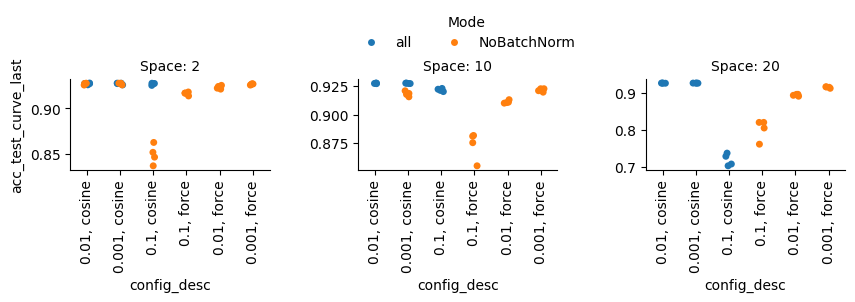

In [150]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_all
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim'])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='acc_test_curve_last', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Mode', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='{row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
# g.set(ylim=(0.31, .36))
# g.set(ylim=(0.9, .93))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

['Gravity' 'Regularizer']


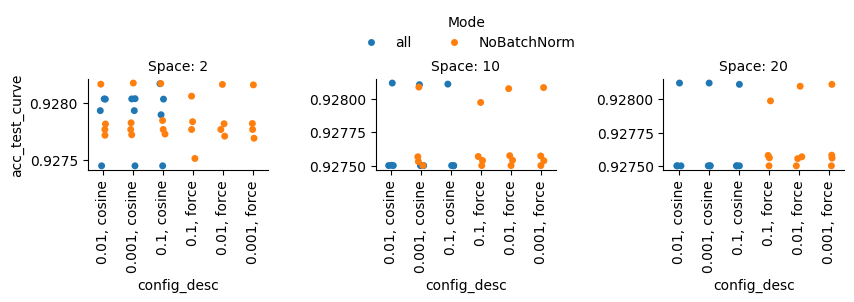

In [153]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_all
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Mode'])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='acc_test_curve', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Mode', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='{row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
# g.set(ylim=(0.31, .36))
# g.set(ylim=(0.9, .93))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

['Gravity' 'Regularizer']


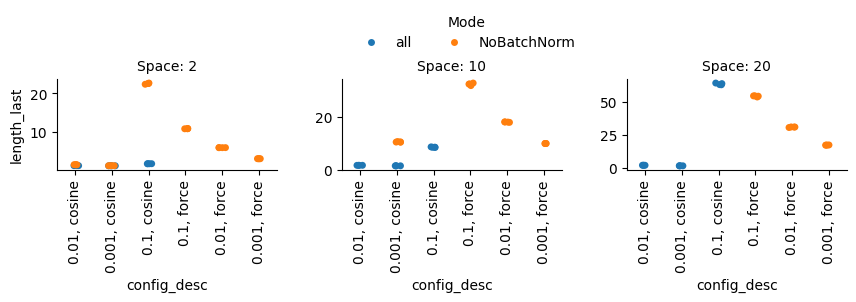

In [154]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_all
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim',])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='length_last', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Mode', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='{row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

['Gravity' 'Regularizer']


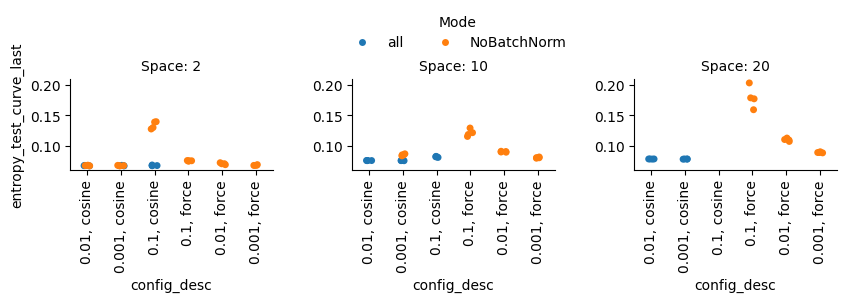

In [155]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_all
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim',])
df_subset.loc[:,'config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='entropy_test_curve_last', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Mode', sharey=False, height=2, aspect=1.5, palette='tab10')
g.set_titles(row_template='{row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()

g.set(ylim=(0.06, .21))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

#### Load single run and analyse

In [33]:
from src.utils import get_params_from_run
import wandb
from src.subspace_curve import RepulsiveCategorySubspace, masked_pytree_to_matrix
import src
from copy import deepcopy

# Load the run from wandb
api = wandb.Api()
run = api.run("ddold/cifar_PtoC/geb03gfo")
config = deepcopy(run.config)

# Load parameters from the run
params_loaded = get_params_from_run(run, file_name_without_id="last_params.npy")
best_params_loaded = get_params_from_run(run, file_name_without_id="params.npy")
init_params_loaded = get_params_from_run(run, file_name_without_id="init_params.npy")

params_loaded

{'batch_stats': {'BatchNorm_0': {'mean': Array([-3.6804096e-05, -7.7708517e-03, -2.9479130e-03, -4.6406314e-03,
           3.8374220e-03, -6.4848466e-03, -9.3490658e-03,  4.9437382e-03,
          -3.8636136e-03,  1.4410674e-03, -2.0307256e-03, -1.1685569e-02,
           8.7189756e-04,  5.2787308e-03,  1.4181972e-02,  3.9420524e-03],      dtype=float32),
   'var': Array([4.0225830e-05, 1.1007804e+00, 1.0252540e-01, 8.1842661e-01,
          9.1552562e-01, 1.1415395e+00, 8.4824520e-01, 3.4484133e-01,
          1.7336348e-01, 1.4061091e+00, 5.3218138e-01, 8.2640231e-01,
          2.6176560e-01, 1.1667830e+00, 1.0312107e+00, 4.1891363e-01],      dtype=float32)},
  'ResNetBlock_0': {'BatchNorm_0': {'mean': Array([-0.6828697 , -0.45956507, -0.33141914, -0.45693672, -0.08527734,
            0.10768621, -0.64537376,  0.5721952 , -0.6488356 , -0.60006815,
           -0.16225378, -0.27885842,  1.3159164 , -0.03387012, -0.16572385,
           -0.24050671], dtype=float32),
    'var': Array([0.14409

In [18]:
# load data
from cifar10_PtoC import load_cifar10
x, y, x_val, y_val, x_test, y_test, data_revert_norm_fn = load_cifar10(
    seed=config['rng_seed'])

Files already downloaded and verified
Files already downloaded and verified


In [19]:
config['net_kwargs']

{'act_fn': 'relu',
 'c_hidden': [16, 32, 64],
 'num_blocks': [3, 3, 3],
 'block_class': 'ResNetBlock',
 'num_classes': 10}

In [30]:
# define model
config['net_kwargs']['act_fn'] = getattr(nn, run.config['net_kwargs']['act_fn'])
config['net_kwargs']['block_class'] = getattr(src.models, run.config['net_kwargs']['block_class'])
resnet20 = ResNet(**config['net_kwargs'])

s_model = RepulsiveCategorySubspace(model=resnet20, 
                                    k=config['curve_params']['k'], 
                                    energy_weakening=config['curve_params']['energy_weakening'], 
                                    gravity=config['curve_params']['gravity'], 
                                    mutuable_param_name="batch_stats",
                                    weight_decay=config['curve_params']['weight_decay'])

mask = s_model.init_mask(x_val[:2], all_curves=True)
s_model.curve_mask = mask

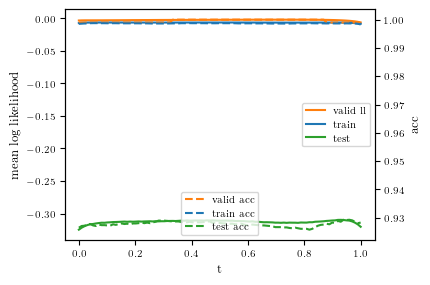

In [32]:
def setup_metrics(model, batch_size, x, target, n_samples, use_linspace=False, average=True):
    if use_linspace:
        def get_t(key): return jnp.linspace(0, 1., n_samples)
    else:
        def get_t(key): return random.uniform(key, (n_samples,), minval=0., maxval=1.)

    def acc_fn(rng_key, params):
        x_ = x.reshape(-1, batch_size, 32, 32, 3)
        y_ = target.reshape(-1, batch_size)

        def pred(key, data):
            x_batch, y_batch = data

            def eval(t):
                logits, _ = model(
                    params['params'], params['batch_stats'], t, x_batch, train=False)  # params, batch_stats, t, x
                loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                    logits=logits, labels=y_batch))
                acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_batch)
                return loss, acc  # mean over batch
            key, subkey = random.split(key)

            # draw 10 samples to approximate curve performance
            t = get_t(subkey)
            loss, acc = jax.vmap(eval)(t)

            if average:
                # mean over samples
                return key, (jnp.mean(loss), jnp.mean(acc))
            else:
                return key, (loss, acc)  # no mean over samples

        # shape (n_data, draws, output_dim)
        rng_key, (loss, acc) = jax.lax.scan(pred, rng_key, (x_, y_))
        loss = jnp.mean(loss, axis=0)
        acc = jnp.mean(acc, axis=0)
        return loss, acc  # mean over epochs
    return acc_fn

fig, ax = plt.subplots(1, 1)
t_space = jnp.linspace(0, 1, 100)
valid_metrics_fn_final = setup_metrics(s_model, 100, x_val, y_val, n_samples=100, use_linspace=True, average=False)
train_metrics_fn_final = setup_metrics(s_model, 100, x, y, n_samples=100, use_linspace=True, average=False)
test_metrics_fn_final = setup_metrics(s_model, 100, x_test, y_test, n_samples=100, use_linspace=True, average=False)



# valid
rng_key = random.PRNGKey(0)
nll, acc = valid_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax.twinx()
ax2.plot(t_space, acc, label="valid acc",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, acc = train_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, acc, label="train acc",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, acc = test_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, acc, label="test acc",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax.set_xlabel("t")
ax.set_ylabel("mean log likelihood")
ax2.set_ylabel("acc")
ax.legend()
ax2.legend(loc='lower center')


In [34]:
cp = masked_pytree_to_matrix(params_loaded['params'], mask, run.config['curve_params']['k'])
cp.shape

(21, 272378)

In [35]:
from src.subspace_curve import bezier_coeff_fn


# define function to compute bezier curve length
bezier_coeff_inv = bezier_coeff_fn(run.config['curve_params']['k'])
def get_d_bezier(t):
    coeff = jax.vmap(bezier_coeff_inv)(t)

    def clousure(cp):
        n = cp.shape[0] - 1
        cp_diff = cp[1:] - cp[:-1]
        return jnp.einsum('tj,j...->t...', coeff, cp_diff) * n
    return clousure

@jit
def bezier_length(cp):
    t = jnp.linspace(0, 1, 1000)
    d_bezier = get_d_bezier(t)
    d_t = jnp.linalg.norm(d_bezier(cp), axis=-1)
    length = jax.scipy.integrate.trapezoid(d_t, t)
    return length

bezier_length(cp)

Array(1.4481478, dtype=float32)

In [36]:
def setup_pred(batch_size, x, target, n_samples, use_linspace=False):
    if use_linspace:
        def get_t(key): return jnp.linspace(0, 1., n_samples)
    else:
        def get_t(key): return random.uniform(key, (n_samples,), minval=0., maxval=1.)

    def preds(rng_key, params):
        x_ = x.reshape(-1, batch_size, 32, 32, 3)
        y_ = target.reshape(-1, batch_size)

        def pred_single_batch_multi_sample(key, data):
            x_batch, y_batch = data

            def eval(t):
                logits, _ = s_model(
                    params['params'], params['batch_stats'], t, x_batch, train=False)  # params, batch_stats, t, x
                return (logits, y_batch)  # mean over batch
            key, subkey = random.split(key)

            # draw 10 samples to approximate curve performance
            t = get_t(subkey)
            return key, jax.vmap(eval)(t)  # no mean over samples

        # shape (n_data, draws, output_dim)
        rng_key, (logits, y_b) = jax.lax.scan(pred_single_batch_multi_sample, rng_key, (x_, y_))
        return logits, y_b  # mean over epochs
    return preds

preds_fn_final = setup_pred(200, x_val, y_val, n_samples=100, use_linspace=True)
logits, y_b = preds_fn_final(rng_key, params_loaded) # shape (n_data, draws, batch, output_dim)
logits = logits.transpose(0,2,1,3).reshape(-1, logits.shape[1], logits.shape[-1])  # shape (n_data * batch, draws, output_dim)
y_b = y_b.transpose(0,2,1).reshape(-1, y_b.shape[1])  # shape (n_data * batch, draws)
logits.shape, y_b.shape

((1000, 100, 10), (1000, 100))

Text(0, 0.5, 'entropy')

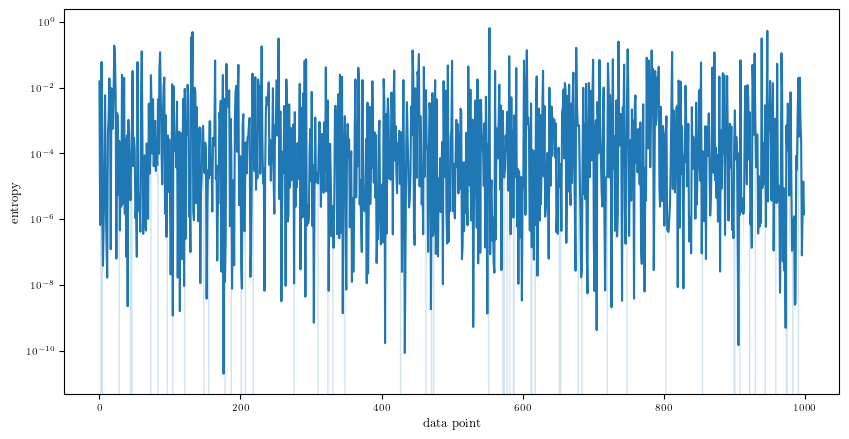

In [37]:
probs = jax.nn.softmax(logits, axis=-1)  # shape (n_data, draws, batch, output_dim)
entropy = - jnp.sum(probs * jnp.log(probs), axis=-1)  # shape (n_data * batch, draws)

plt.figure(figsize=(10, 5))
plt.plot(entropy.mean(-1), label="mean entropy")
plt.fill_between(np.arange(entropy.shape[0]),
                 entropy.mean(-1) - entropy.std(-1),
                 entropy.mean(-1) + entropy.std(-1), alpha=0.2, label="std")
plt.yscale('log')
plt.xlabel("data point")
plt.ylabel("entropy")

/tmp/ipykernel_730333/2652488478.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


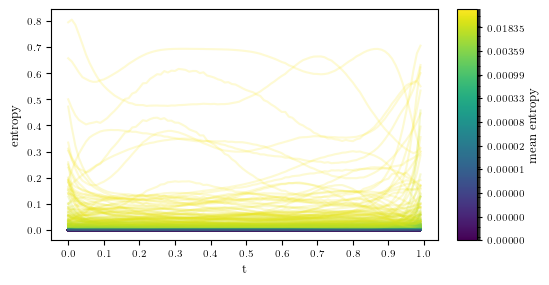

In [38]:
# plt.plot(entropy.T, color='C0', alpha=0.1)
# plt.xlabel("t")
# plt.xticks(np.arange(0, 110, 10), np.round(np.linspace(0, 1, 11), 2))
# Color each line by its mean entropy value
import matplotlib.cm as cm
from matplotlib.colors import BoundaryNorm, LogNorm

mean_entropy = entropy.mean(axis=1)

quantiles = np.quantile(mean_entropy, np.linspace(0, 1, 255))
norm = BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)
# norm = LogNorm(mean_entropy.min(), mean_entropy.max())
cmap = cm.get_cmap('viridis')

plt.figure(figsize=(5, 3))

for i in range(entropy.shape[0]):
    plt.plot(entropy[i], color=cmap(norm(mean_entropy[i])), alpha=0.2)

plt.ylabel("entropy")
plt.xlabel("t")
plt.xticks(np.arange(0, 110, 10), np.round(np.linspace(0, 1, 11), 2))
plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), label='mean entropy', cax=plt.gca().inset_axes([1.05, 0, 0.05, 1]))

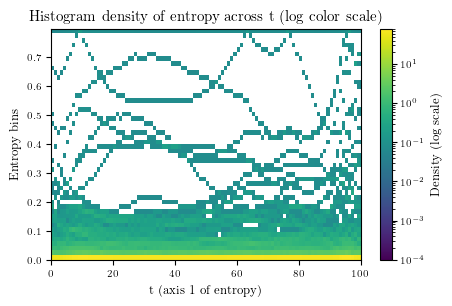

In [39]:
from matplotlib.colors import LogNorm

import matplotlib.pyplot as plt

# Compute histogram for each column (axis=1) of entropy
n_bins = 50
hist_data = []
bin_edges = None

for i in range(entropy.shape[1]):
    hist, bins = np.histogram(entropy[:, i], bins=n_bins, density=True)
    hist_data.append(hist)
    if bin_edges is None:
        bin_edges = bins

hist_data = np.array(hist_data).T  # shape: (n_bins, shape[1])

# Prepare meshgrid for pcolormesh
X, Y = np.meshgrid(np.arange(entropy.shape[1]+1), bin_edges)

plt.figure(figsize=(5, 3))
pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis', norm=LogNorm(vmax=hist_data.max(), vmin=1e-4))
# pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis')
plt.colorbar(pcm, label='Density (log scale)')
plt.xlabel('t (axis 1 of entropy)')
plt.ylabel('Entropy bins')
plt.title('Histogram density of entropy across t (log color scale)')
plt.show()

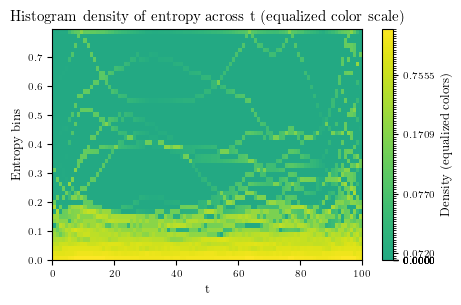

In [40]:
from matplotlib.colors import BoundaryNorm

import matplotlib.pyplot as plt

# Compute histogram for each column (axis=1) of entropy
n_bins = 50
hist_data = []
bin_edges = None

for i in range(entropy.shape[1]):
    hist, bins = np.histogram(entropy[:, i], bins=n_bins, density=True)
    hist_data.append(hist)
    if bin_edges is None:
        bin_edges = bins

hist_data = np.array(hist_data).T  # shape: (n_bins, shape[1])

# Prepare meshgrid for pcolormesh
X, Y = np.meshgrid(np.arange(entropy.shape[1]+1), bin_edges)

# Compute quantiles for equal representation
flat_hist = hist_data.flatten()
quantiles = np.quantile(flat_hist, np.linspace(0, 1, 255))
norm = BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)

plt.figure(figsize=(5,3))
pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis', norm=norm)
plt.colorbar(pcm, label='Density (equalized colors)')
plt.xlabel('t')
plt.ylabel('Entropy bins')
plt.title('Histogram density of entropy across t (equalized color scale)')
plt.show()

Max entropy index: 553, mean entropy: 0.6377441883087158


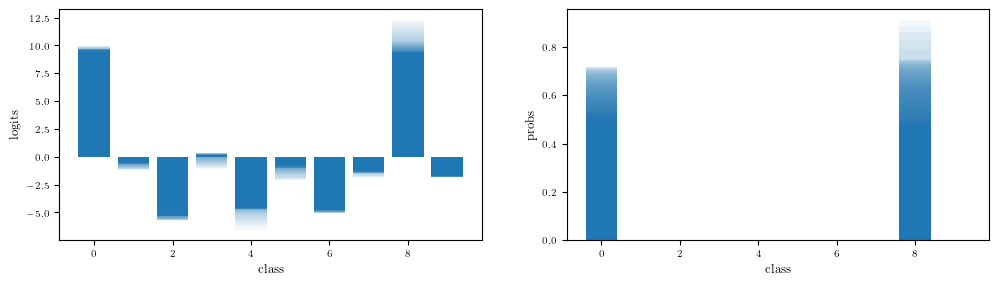

In [41]:
# max entropy example
max_idx = np.argmax(mean_entropy)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[max_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[max_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Max entropy index: {max_idx}, mean entropy: {mean_entropy[max_idx]}")


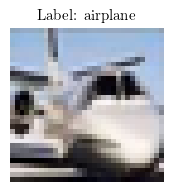

In [42]:
cifar10_label = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(2, 2))
plt.imshow(data_revert_norm_fn(x_val[max_idx]))
plt.title(f"Label: {cifar10_label[y_val[max_idx]]}")
plt.axis('off')
plt.show()

Min entropy index: 176, mean entropy: 1.9819057853198707e-11


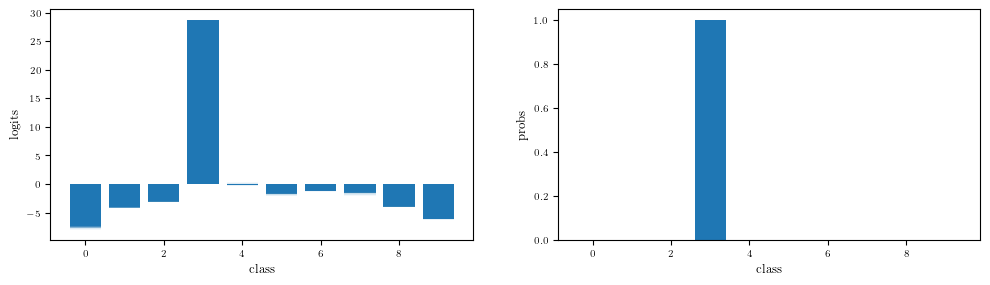

In [43]:
# min entropy example
min_idx = np.argmin(mean_entropy)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[min_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[min_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Min entropy index: {min_idx}, mean entropy: {mean_entropy[min_idx]}")

Max std index according logits: 46, mean entropy: 0.0006048672366887331


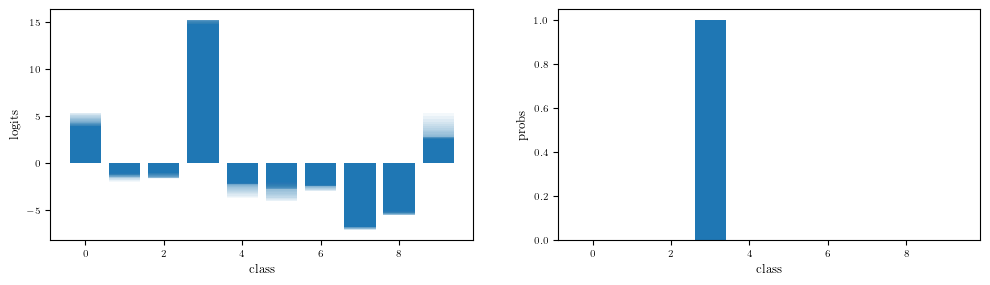

In [44]:
mean_per_class_std = logits.std(axis=1).mean(-1)
max_idx = np.argmax(mean_per_class_std)

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[max_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[max_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Max std index according logits: {max_idx}, mean entropy: {mean_entropy[max_idx]}")


In [ ]:
print("Entropy Metrics:")
print(f"Mean: {entropy.mean():.5f}, Std: {entropy.std(-1).mean():.5f}, Max: {entropy.max(-1).mean():.5f} ")

Entropy Metrics:
Mean: 0.00845, Std: 0.00280, Max: 0.01875 


##### Load model with long length and acc > 0.9

In [ ]:
# Load the run from wandb
api = wandb.Api()
run = api.run("ddold/cifar_PtoC/sydj7pem")

# Load parameters from the run
params_loaded = get_params_from_run(run, file_name_without_id="last_params.npy")
best_params_loaded = get_params_from_run(run, file_name_without_id="params.npy")
init_params_loaded = get_params_from_run(run, file_name_without_id="init_params.npy")

params_loaded

{'batch_stats': {'BatchNorm_0': {'mean': Array([-2.0290161e-05, -7.6166154e-03, -3.6669490e-03, -4.6294904e-03,
           3.0253346e-03, -5.8202762e-03, -7.7069127e-03,  3.2531638e-03,
          -4.1186772e-03,  1.1250727e-03, -7.7792886e-04, -9.8135481e-03,
          -2.8501128e-04,  7.3805009e-03,  1.3374743e-02,  3.3389695e-03],      dtype=float32),
   'var': Array([7.9450285e-05, 1.1076356e+00, 1.1277322e-01, 8.2194418e-01,
          9.0484321e-01, 1.1396474e+00, 8.3294958e-01, 3.3709174e-01,
          1.7690128e-01, 1.4155055e+00, 5.3009218e-01, 8.1745970e-01,
          2.5517544e-01, 1.1703615e+00, 1.0453932e+00, 4.2623651e-01],      dtype=float32)},
  'ResNetBlock_0': {'BatchNorm_0': {'mean': Array([-0.69910175, -0.4320296 , -0.3343934 , -0.46736357, -0.08912051,
            0.09221624, -0.6390792 ,  0.5765417 , -0.6590047 , -0.6023606 ,
           -0.15886454, -0.26726514,  1.3305398 , -0.02819552, -0.17778479,
           -0.22308455], dtype=float32),
    'var': Array([0.15336

In [ ]:
cp = pytree_to_matrix(params_loaded['params'], run.config['curve_params']['k'])

from src.subspace_curve import bezier_coeff_fn


# define function to compute bezier curve length
bezier_coeff_inv = bezier_coeff_fn(run.config['curve_params']['k'])
def get_d_bezier(t):
    coeff = jax.vmap(bezier_coeff_inv)(t)

    def clousure(cp):
        n = cp.shape[0] - 1
        cp_diff = cp[1:] - cp[:-1]
        return jnp.einsum('tj,j...->t...', coeff, cp_diff) * n
    return clousure

@jit
def bezier_length(cp):
    t = jnp.linspace(0, 1, 1000)
    d_bezier = get_d_bezier(t)
    d_t = jnp.linalg.norm(d_bezier(cp), axis=-1)
    length = jax.scipy.integrate.trapezoid(d_t, t)
    return length

bezier_length(cp)

Array(28.302818, dtype=float32)

In [ ]:
preds_fn_final = setup_pred(200, x_val, y_val, n_samples=100, use_linspace=True)
logits, y_b = preds_fn_final(rng_key, params_loaded) # shape (n_data, draws, batch, output_dim)
logits = logits.transpose(0,2,1,3).reshape(-1, logits.shape[1], logits.shape[-1])  # shape (n_data * batch, draws, output_dim)
y_b = y_b.transpose(0,2,1).reshape(-1, y_b.shape[1])  # shape (n_data * batch, draws)

probs = jax.nn.softmax(logits, axis=-1)  # shape (n_data, draws, batch, output_dim)
entropy = - jnp.sum(probs * jnp.log(probs), axis=-1)  # shape (n_data * batch, draws)
mean_entropy = entropy.mean(axis=1)

logits.shape, y_b.shape

((1000, 100, 10), (1000, 100))

/tmp/ipykernel_403065/4102112847.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


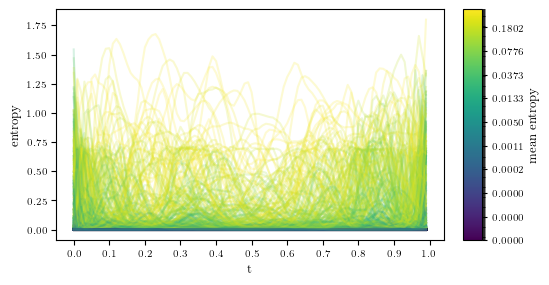

In [ ]:
# plt.plot(entropy.T, color='C0', alpha=0.1)
# plt.xlabel("t")
# plt.xticks(np.arange(0, 110, 10), np.round(np.linspace(0, 1, 11), 2))
# Color each line by its mean entropy value
import matplotlib.cm as cm
from matplotlib.colors import BoundaryNorm, LogNorm
plt.figure(figsize=(5, 3))

mean_entropy = entropy.mean(axis=1)

quantiles = np.quantile(mean_entropy, np.linspace(0, 1, 255))
norm = BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)
# norm = LogNorm(mean_entropy.min(), mean_entropy.max())
cmap = cm.get_cmap('viridis')

for i in range(entropy.shape[0]):
    plt.plot(entropy[i], color=cmap(norm(mean_entropy[i])), alpha=0.2)

plt.ylabel("entropy")
plt.xlabel("t")
plt.xticks(np.arange(0, 110, 10), np.round(np.linspace(0, 1, 11), 2))
plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), label='mean entropy', cax=plt.gca().inset_axes([1.05, 0, 0.05, 1]))

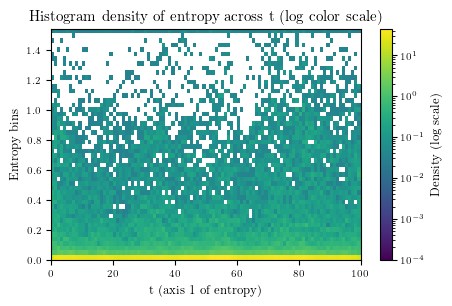

In [ ]:
from matplotlib.colors import LogNorm

import matplotlib.pyplot as plt

# Compute histogram for each column (axis=1) of entropy
n_bins = 50
hist_data = []
bin_edges = None

for i in range(entropy.shape[1]):
    hist, bins = np.histogram(entropy[:, i], bins=n_bins, density=True)
    hist_data.append(hist)
    if bin_edges is None:
        bin_edges = bins

hist_data = np.array(hist_data).T  # shape: (n_bins, shape[1])

# Prepare meshgrid for pcolormesh
X, Y = np.meshgrid(np.arange(entropy.shape[1]+1), bin_edges)

plt.figure(figsize=(5, 3))
pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis', norm=LogNorm(vmax=hist_data.max(), vmin=1e-4))
# pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis')
plt.colorbar(pcm, label='Density (log scale)')
plt.xlabel('t (axis 1 of entropy)')
plt.ylabel('Entropy bins')
plt.title('Histogram density of entropy across t (log color scale)')
plt.show()

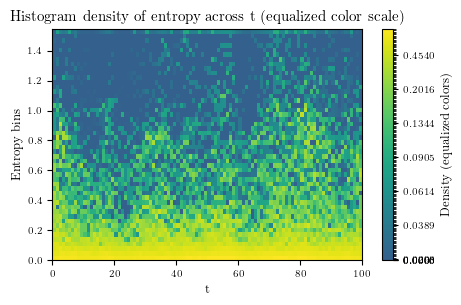

In [ ]:
from matplotlib.colors import BoundaryNorm

import matplotlib.pyplot as plt

# Compute histogram for each column (axis=1) of entropy
n_bins = 50
hist_data = []
bin_edges = None

for i in range(entropy.shape[1]):
    hist, bins = np.histogram(entropy[:, i], bins=n_bins, density=True)
    hist_data.append(hist)
    if bin_edges is None:
        bin_edges = bins

hist_data = np.array(hist_data).T  # shape: (n_bins, shape[1])

# Prepare meshgrid for pcolormesh
X, Y = np.meshgrid(np.arange(entropy.shape[1]+1), bin_edges)

# Compute quantiles for equal representation
flat_hist = hist_data.flatten()
quantiles = np.quantile(flat_hist, np.linspace(0, 1, 255))
norm = BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)

plt.figure(figsize=(5, 3))
pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis', norm=norm)
plt.colorbar(pcm, label='Density (equalized colors)')
plt.xlabel('t')
plt.ylabel('Entropy bins')
plt.title('Histogram density of entropy across t (equalized color scale)')
plt.show()

Max entropy index: 132, mean entropy: 0.7210912704467773


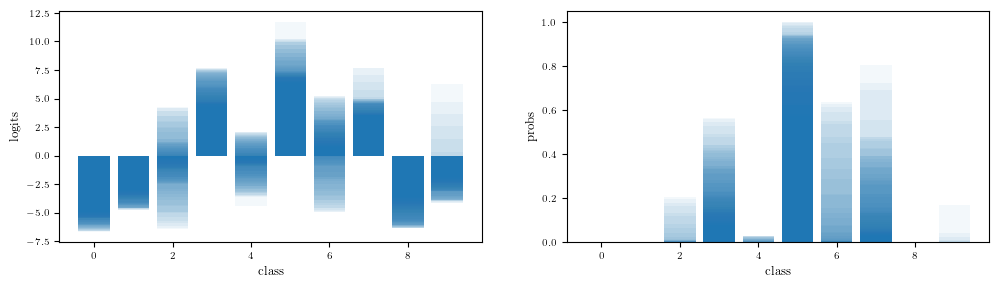

In [ ]:
# max entropy example
max_idx = np.argmax(mean_entropy)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[max_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[max_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Max entropy index: {max_idx}, mean entropy: {mean_entropy[max_idx]}")


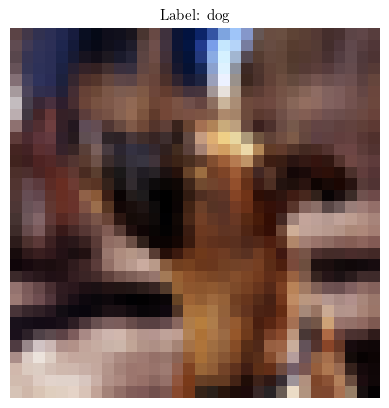

In [ ]:
cifar10_label = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

plt.imshow(data_revert_norm_fn(x_val[max_idx]))
plt.title(f"Label: {cifar10_label[y_val[max_idx]]}")
plt.axis('off')
plt.show()

Min entropy index: 705, mean entropy: 1.3659048336833735e-09


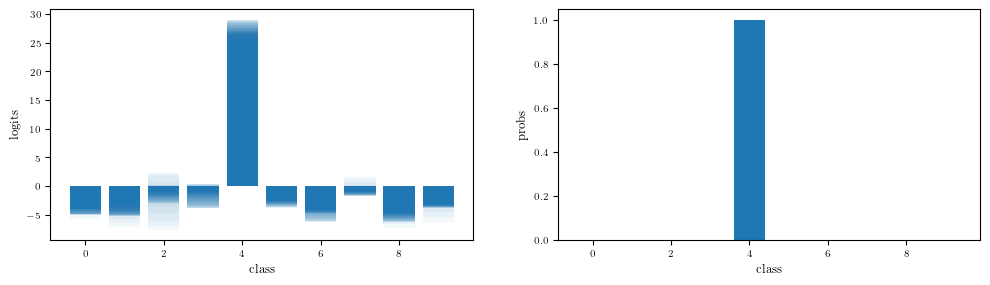

In [ ]:
# min entropy example
min_idx = np.argmin(mean_entropy)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[min_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[min_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Min entropy index: {min_idx}, mean entropy: {mean_entropy[min_idx]}")

Max std index according logits: 119, mean entropy: 0.12797650694847107


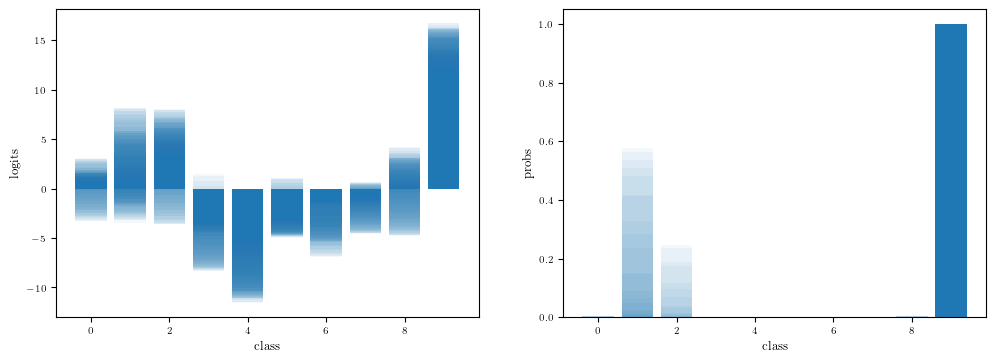

In [ ]:
mean_per_class_std = logits.std(axis=1).mean(-1)
max_idx = np.argmax(mean_per_class_std)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[max_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[max_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Max std index according logits: {max_idx}, mean entropy: {mean_entropy[max_idx]}")


In [ ]:
print("Entropy Metrics:")
print(f"Mean: {entropy.mean():.5f}, Std: {entropy.std(-1).mean():.5f}, Max: {entropy.max(-1).mean():.5f} ")

Entropy Metrics:
Mean: 0.04520, Std: 0.06770, Max: 0.30500 


##### Load model with long length

In [ ]:
# Load the run from wandb
api = wandb.Api()
run = api.run("ddold/cifar_PtoC/q0fhyzwa")

# Load parameters from the run
params_loaded = get_params_from_run(run, file_name_without_id="last_params.npy")
best_params_loaded = get_params_from_run(run, file_name_without_id="params.npy")
init_params_loaded = get_params_from_run(run, file_name_without_id="init_params.npy")

params_loaded

{'batch_stats': {'BatchNorm_0': {'mean': Array([-2.1548110e-05, -8.3743576e-03, -4.8624366e-03, -4.6018548e-03,
           1.4847839e-03, -3.6085136e-03, -7.4172621e-03,  3.4638492e-03,
          -4.1692802e-03,  6.5153907e-04,  8.6335640e-04, -9.5279953e-03,
          -1.3665263e-04,  5.6423857e-03,  1.4264775e-02,  2.5753037e-03],      dtype=float32),
   'var': Array([4.0192150e-05, 1.1136501e+00, 1.9768310e-01, 8.1781667e-01,
          9.3020451e-01, 1.3399532e+00, 8.5890579e-01, 3.2734665e-01,
          1.8599336e-01, 1.4184471e+00, 5.3542173e-01, 7.9969841e-01,
          2.7748662e-01, 1.1586426e+00, 1.0320315e+00, 4.4740561e-01],      dtype=float32)},
  'ResNetBlock_0': {'BatchNorm_0': {'mean': Array([-0.6701694 , -0.46792266, -0.3142442 , -0.3966021 , -0.11668126,
            0.10005353, -0.684607  ,  0.56768245, -0.6505161 , -0.5956916 ,
           -0.17929275, -0.26873916,  1.3741232 , -0.02407709, -0.1478268 ,
           -0.24478309], dtype=float32),
    'var': Array([0.16226

In [ ]:
cp = pytree_to_matrix(params_loaded['params'], run.config['curve_params']['k'])

from src.subspace_curve import bezier_coeff_fn


# define function to compute bezier curve length
bezier_coeff_inv = bezier_coeff_fn(run.config['curve_params']['k'])
def get_d_bezier(t):
    coeff = jax.vmap(bezier_coeff_inv)(t)

    def clousure(cp):
        n = cp.shape[0] - 1
        cp_diff = cp[1:] - cp[:-1]
        return jnp.einsum('tj,j...->t...', coeff, cp_diff) * n
    return clousure

@jit
def bezier_length(cp):
    t = jnp.linspace(0, 1, 1000)
    d_bezier = get_d_bezier(t)
    d_t = jnp.linalg.norm(d_bezier(cp), axis=-1)
    length = jax.scipy.integrate.trapezoid(d_t, t)
    return length

bezier_length(cp)

Array(53.79383, dtype=float32)

In [ ]:
preds_fn_final = setup_pred(200, x_val, y_val, n_samples=100, use_linspace=True)
logits, y_b = preds_fn_final(rng_key, params_loaded) # shape (n_data, draws, batch, output_dim)
logits = logits.transpose(0,2,1,3).reshape(-1, logits.shape[1], logits.shape[-1])  # shape (n_data * batch, draws, output_dim)
y_b = y_b.transpose(0,2,1).reshape(-1, y_b.shape[1])  # shape (n_data * batch, draws)

probs = jax.nn.softmax(logits, axis=-1)  # shape (n_data, draws, batch, output_dim)
entropy = - jnp.sum(probs * jnp.log(probs), axis=-1)  # shape (n_data * batch, draws)
mean_entropy = entropy.mean(axis=1)

logits.shape, y_b.shape

((1000, 100, 10), (1000, 100))

/tmp/ipykernel_403065/4102112847.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


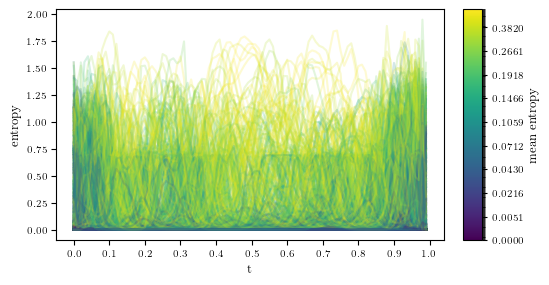

In [ ]:
# plt.plot(entropy.T, color='C0', alpha=0.1)
# plt.xlabel("t")
# plt.xticks(np.arange(0, 110, 10), np.round(np.linspace(0, 1, 11), 2))
# Color each line by its mean entropy value
import matplotlib.cm as cm
from matplotlib.colors import BoundaryNorm, LogNorm
plt.figure(figsize=(5, 3))

mean_entropy = entropy.mean(axis=1)

quantiles = np.quantile(mean_entropy, np.linspace(0, 1, 255))
norm = BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)
# norm = LogNorm(mean_entropy.min(), mean_entropy.max())
cmap = cm.get_cmap('viridis')

for i in range(entropy.shape[0]):
    plt.plot(entropy[i], color=cmap(norm(mean_entropy[i])), alpha=0.2)

plt.ylabel("entropy")
plt.xlabel("t")
plt.xticks(np.arange(0, 110, 10), np.round(np.linspace(0, 1, 11), 2))
plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), label='mean entropy', cax=plt.gca().inset_axes([1.05, 0, 0.05, 1]))

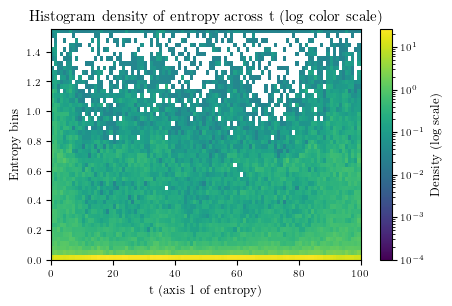

In [ ]:
from matplotlib.colors import LogNorm

import matplotlib.pyplot as plt

# Compute histogram for each column (axis=1) of entropy
n_bins = 50
hist_data = []
bin_edges = None

for i in range(entropy.shape[1]):
    hist, bins = np.histogram(entropy[:, i], bins=n_bins, density=True)
    hist_data.append(hist)
    if bin_edges is None:
        bin_edges = bins

hist_data = np.array(hist_data).T  # shape: (n_bins, shape[1])

# Prepare meshgrid for pcolormesh
X, Y = np.meshgrid(np.arange(entropy.shape[1]+1), bin_edges)

plt.figure(figsize=(5, 3))
pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis', norm=LogNorm(vmax=hist_data.max(), vmin=1e-4))
# pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis')
plt.colorbar(pcm, label='Density (log scale)')
plt.xlabel('t (axis 1 of entropy)')
plt.ylabel('Entropy bins')
plt.title('Histogram density of entropy across t (log color scale)')
plt.show()

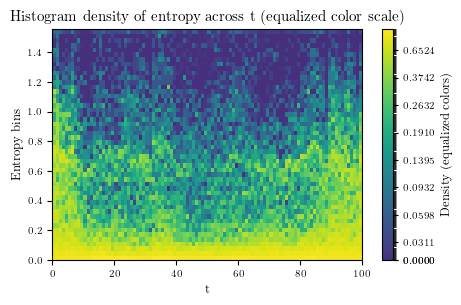

In [ ]:
from matplotlib.colors import BoundaryNorm

import matplotlib.pyplot as plt

# Compute histogram for each column (axis=1) of entropy
n_bins = 50
hist_data = []
bin_edges = None

for i in range(entropy.shape[1]):
    hist, bins = np.histogram(entropy[:, i], bins=n_bins, density=True)
    hist_data.append(hist)
    if bin_edges is None:
        bin_edges = bins

hist_data = np.array(hist_data).T  # shape: (n_bins, shape[1])

# Prepare meshgrid for pcolormesh
X, Y = np.meshgrid(np.arange(entropy.shape[1]+1), bin_edges)

# Compute quantiles for equal representation
flat_hist = hist_data.flatten()
quantiles = np.quantile(flat_hist, np.linspace(0, 1, 255))
norm = BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)

plt.figure(figsize=(5, 3))
pcm = plt.pcolormesh(X, Y, hist_data, shading='auto', cmap='viridis', norm=norm)
plt.colorbar(pcm, label='Density (equalized colors)')
plt.xlabel('t')
plt.ylabel('Entropy bins')
plt.title('Histogram density of entropy across t (equalized color scale)')
plt.show()

Max entropy index: 793, mean entropy: 0.8788015842437744


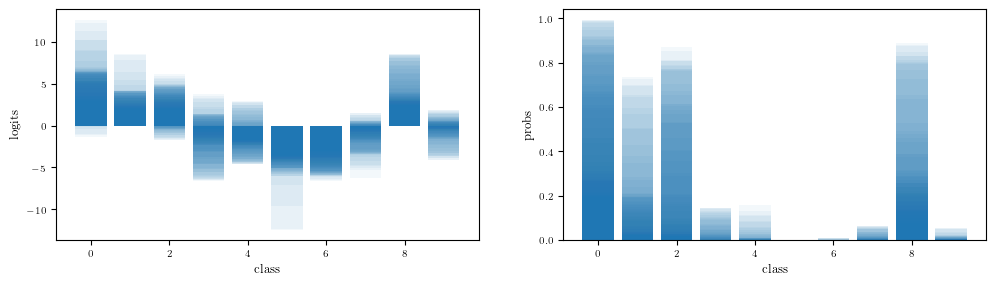

In [ ]:
# max entropy example
max_idx = np.argmax(mean_entropy)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[max_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[max_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Max entropy index: {max_idx}, mean entropy: {mean_entropy[max_idx]}")


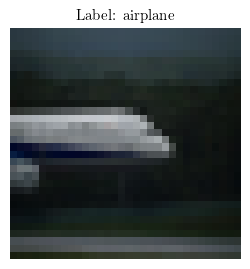

In [ ]:
cifar10_label = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(3,3))
plt.imshow(data_revert_norm_fn(x_val[max_idx]))
plt.title(f"Label: {cifar10_label[y_val[max_idx]]}")
plt.axis('off')
plt.show()

Min entropy index: 514, mean entropy: 1.2866797760580084e-06


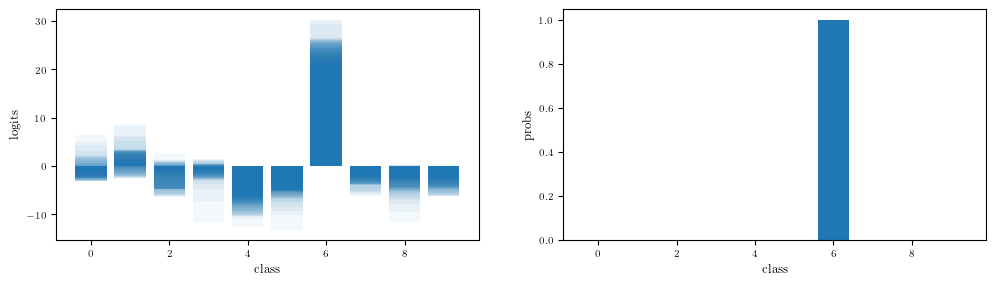

In [ ]:
# min entropy example
min_idx = np.argmin(mean_entropy)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[min_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[min_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Min entropy index: {min_idx}, mean entropy: {mean_entropy[min_idx]}")

Max std index according logits: 328, mean entropy: 0.183643639087677


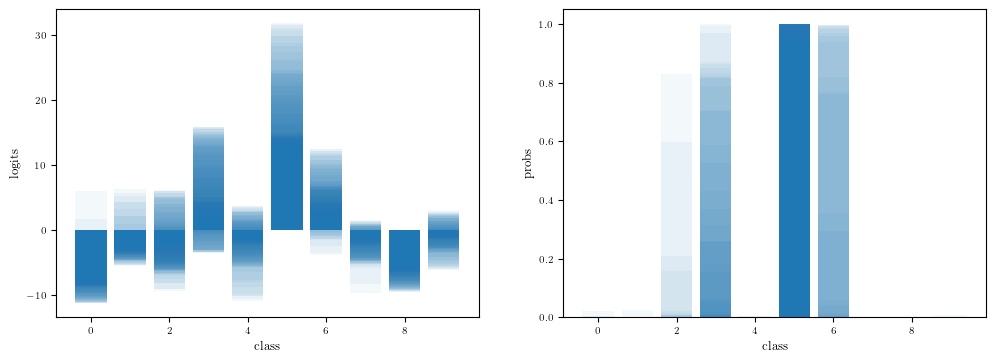

In [ ]:
mean_per_class_std = logits.std(axis=1).mean(-1)
max_idx = np.argmax(mean_per_class_std)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i in range(logits.shape[1]):
    ax[0].bar(x=np.arange(0, 10, 1), height=logits[max_idx, i], alpha=0.05, color='C0')
    ax[1].bar(x=np.arange(0, 10, 1), height=probs[max_idx, i], alpha=0.05, color='C0')
ax[0].set_xlabel("class")
ax[1].set_xlabel("class")
ax[0].set_ylabel("logits")
ax[1].set_ylabel("probs")
print(f"Max std index according logits: {max_idx}, mean entropy: {mean_entropy[max_idx]}")


### ToyRegression analyse

In [2]:
api = wandb.Api()
results = []
for s_id in ['kino2oun',]:
    t_bar = tqdm(api.sweep(f"ddold/toyReg_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            # art = run.used_artifacts()[1]
            # point_performance = art.logged_by().summary.get('nll_test_curve', np.nan)
            
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       Seed=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       EnergyWeakening=run.config['curve_params']['energy_weakening'],
                       Regularizer=run.config['curve_params']['regularizer'],
                       ParamsPath=run.config['params_path'].replace("ddold/toyReg_PtoC/params:", ""),
                       mse_test=run.summary.get('mse_test_curve', np.nan),
                       mse_test_last=run.summary.get('mse_test_curve_last', np.nan),
                       mse_val=run.summary.get('mse_val_curve', np.nan),
                       mse_val_last=run.summary.get('mse_val_curve_last', np.nan),
                       nll_test=run.summary.get('nll_test_curve', np.nan),
                       nll_test_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val=run.summary.get('nll_val_curve', np.nan),
                       nll_val_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),
                       cosine_similarity=run.summary.get('cosine_similarity', np.nan),
                       sample_std_best=run.summary.get('Sample Std best', np.nan),
                       sample_std_last=run.summary.get('Sample Std last', np.nan),
                       init_test_loss=run.summary.get('init_test_loss', np.nan),
                       init_val_loss=run.summary.get('init_val_loss', np.nan),
                    #    init_point_performance=point_performance,
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df = pd.DataFrame(results)
df

Sweep id: kino2oun:   0%|          | 0/576 [00:00<?, ?it/s, polar-sweep-557]   

Sweep id: kino2oun: 100%|██████████| 576/576 [00:01<00:00, 385.44it/s, legendary-sweep-1]      


,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,nll_test_last,nll_val,nll_val_last,length_best,length_last,cosine_similarity,sample_std_best,sample_std_last,init_test_loss,init_val_loss
0,2owgrada,20,4,1.000000e-08,1.0,0,False,2000,0.0003,1,...,1.219315,-1.876440,1.215595,0.025049,76.930573,0.000095,0.002601,0.818620,-1.288248,-1.873585
1,2n8zbg34,20,3,1.000000e-08,1.0,0,False,2000,0.0003,1,...,2.603427,-1.877008,2.602182,0.013384,71.383278,0.000030,0.002118,2.976406,-1.288249,-1.873585
2,hqbjf1vt,20,1,1.000000e-08,1.0,0,False,2000,0.0003,1,...,1.311521,-1.877210,1.306823,0.018350,84.674202,0.000045,0.002344,0.863977,-1.288248,-1.873585
3,a6cgka5h,20,0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,2.812646,-1.876504,2.870203,0.011866,90.203522,0.000048,0.001931,1.007576,-1.288248,-1.873585
4,t2n62wrb,20,4,1.000000e-08,1.0,0,False,2000,0.0003,1,...,0.794490,-1.623397,0.601701,0.013810,80.958641,0.000053,0.002778,0.421060,1.424805,-1.620949
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,fabu0pll,2,0,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.117079,-1.690048,-1.517040,0.002954,0.137031,0.999943,0.000553,0.006659,-1.338157,-1.686955
572,y8451gvc,2,4,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.451980,-1.760908,-1.698145,0.033495,0.119537,0.999956,0.004710,0.006474,-1.350388,-1.738296
573,tirm7ipr,2,3,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.469655,-1.767003,-1.701199,0.021035,0.114637,0.999960,0.001535,0.004179,-1.350388,-1.738296
574,jpliaqvw,2,1,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.456488,-1.768074,-1.688492,0.032722,0.118290,0.999957,0.001694,0.007441,-1.350388,-1.738296


In [3]:
init_point_performance_test = {}
init_point_performance_valid = {}
for run in api.runs("ddold/toyReg_PtoC"):
    if "single" in run.name:
        id_ = run.logged_artifacts()[1].name.split(':')[1]
        init_point_performance_test[id_] = run.summary['nll_test_curve']
        init_point_performance_valid[id_] = run.summary['nll_val_curve']
init_point_performance_valid

{'v22': -1.8732540607452393,
 'v23': -1.6230748891830444,
 'v24': -1.5111514329910278,
 'v25': -1.644564151763916,
 'v26': -1.688456654548645,
 'v27': -1.7386547327041626}

In [4]:
# runs with NaN values in the config
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan]

,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,nll_test_last,nll_val,nll_val_last,length_best,length_last,cosine_similarity,sample_std_best,sample_std_last,init_test_loss,init_val_loss
11,fx6qa58n,20,0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,NaN,-1.510095,NaN,0.0007,NaN,0.020261,0.00012,NaN,-1.08819,-1.510316


In [5]:
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
print("Runs with problems: \n", df[idx_config_with_nan]['Id'])
print()

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)

print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and (c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
variable_idx

Runs with problems: 
 11    fx6qa58n
Name: Id, dtype: object

Unique configuartions: 
SubspaceDim [20 10  2]
Seed [4 3 1 0]
Jitter [1.e-08]
Gravity [1.   0.1  0.01 0.  ]
WeightDecay [0]
RemoveInitialPermutation [False]
Epochs [2000]
Lr [0.0003]
EnergyWeakening [1]
Regularizer ['cosine' 'force']
ParamsPath ['v22' 'v23' 'v24' 'v25' 'v26' 'v27']

Experiment differs in ['SubspaceDim', 'Gravity', 'Regularizer', 'ParamsPath'] configs


['SubspaceDim', 'Gravity', 'Regularizer', 'ParamsPath']

#### Print test performance last

/tmp/ipykernel_730333/1683319169.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity' 'Regularizer']


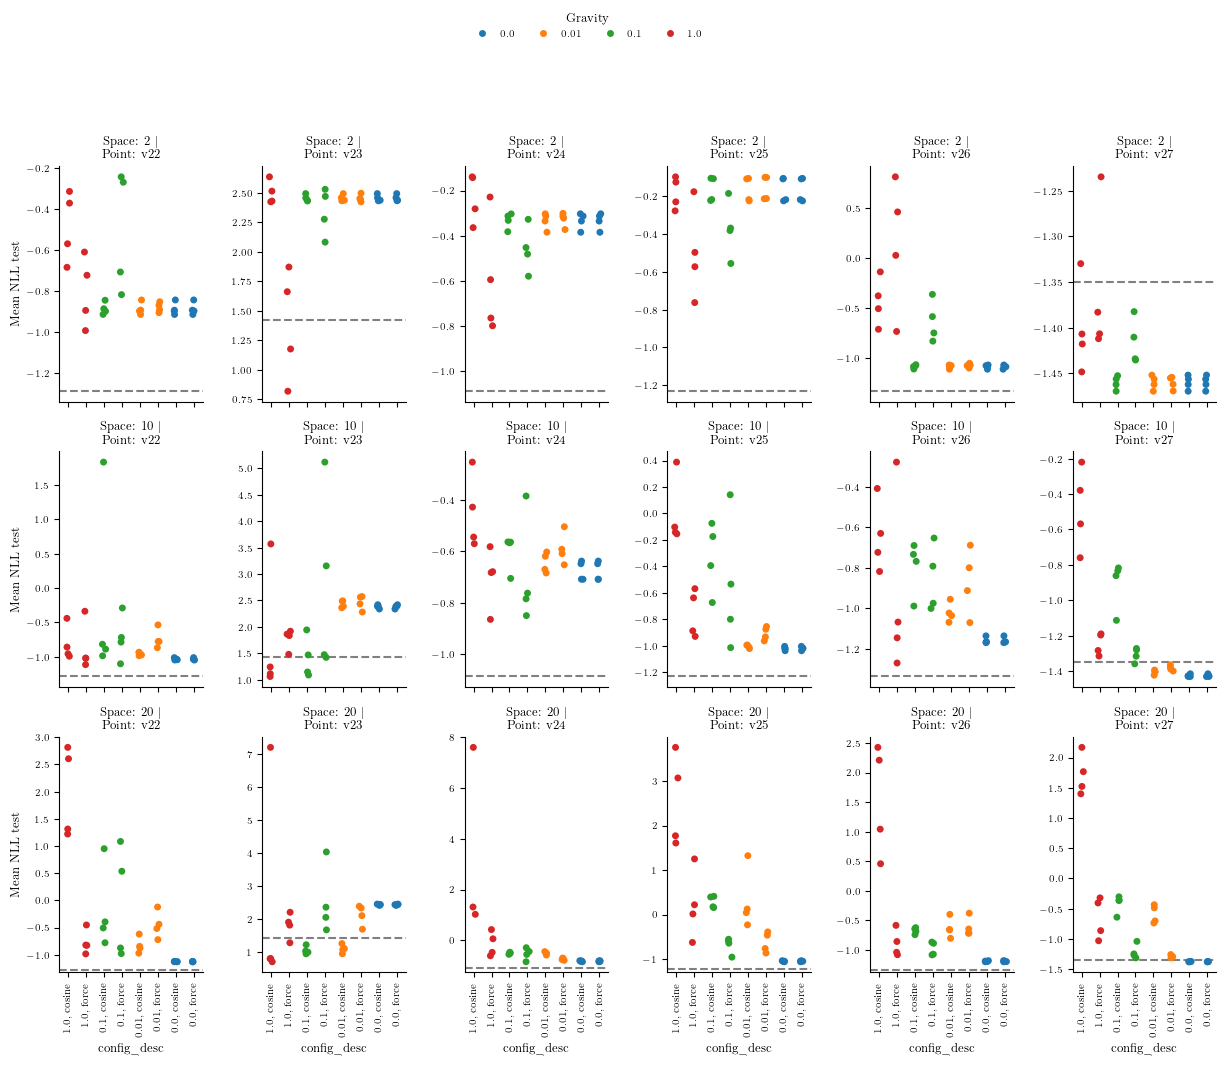

In [109]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='nll_test_last', x='config_desc',
                row='SubspaceDim', col='ParamsPath', kind='strip', hue='Gravity', sharey=False, height=3, aspect=0.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nPoint: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL test")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)
# Add horizontal lines for each ParamsPath column using init_point_performance_test
for ax, params_path in zip(g.axes[0].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[1].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[2].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')


/tmp/ipykernel_730333/3246447191.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity' 'Regularizer']


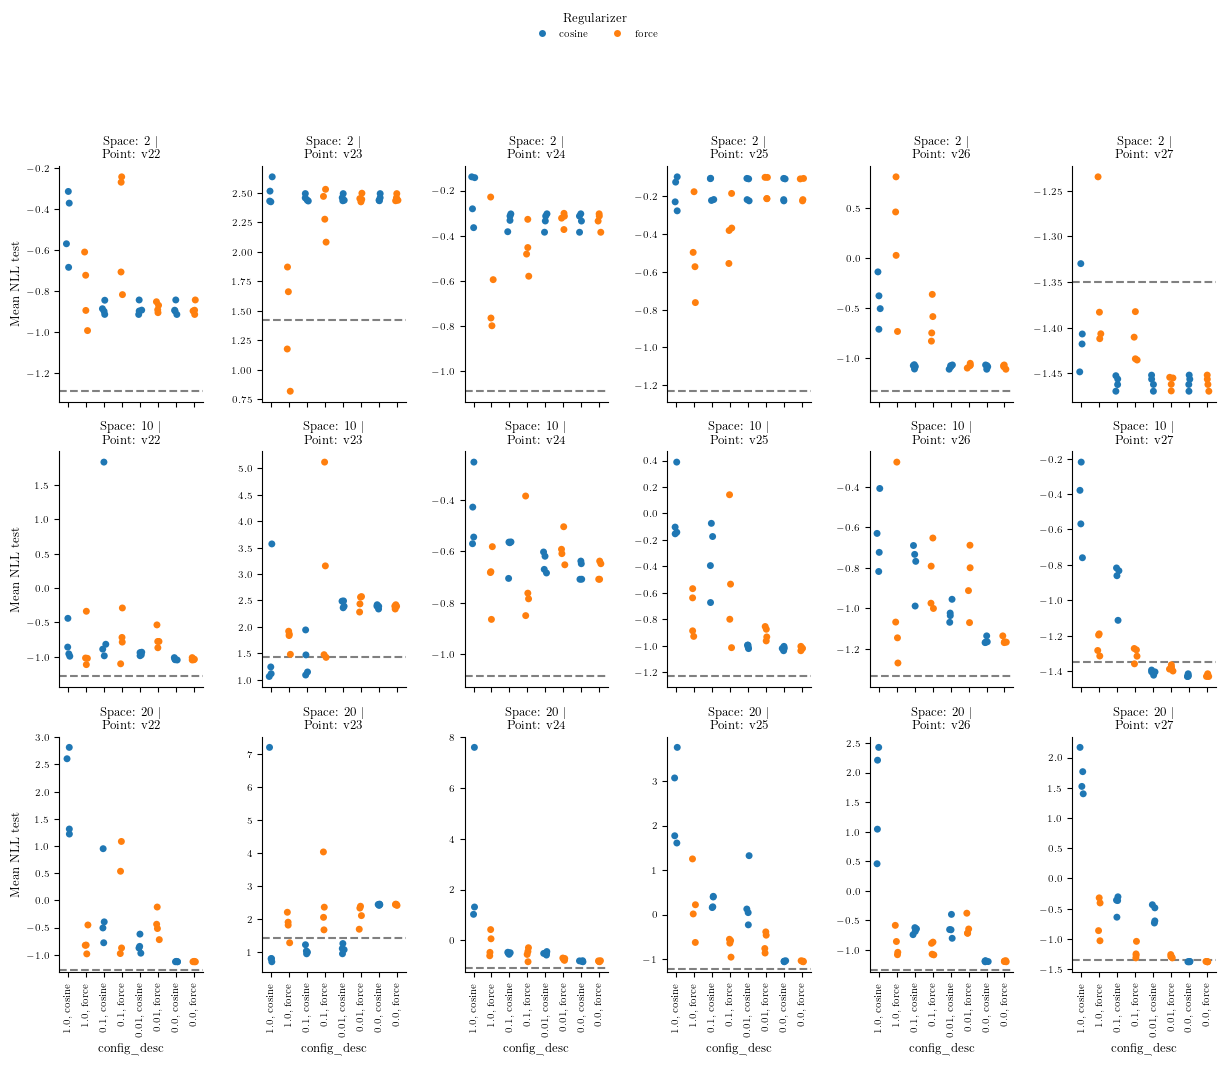

In [110]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='nll_test_last', x='config_desc',
                row='SubspaceDim', col='ParamsPath', kind='strip', hue='Regularizer', sharey=False, height=3, aspect=0.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nPoint: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL test")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

# Add horizontal lines for each ParamsPath column using init_point_performance_test
for ax, params_path in zip(g.axes[0].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[1].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[2].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')

#### Print test performance from best model according validation data

/tmp/ipykernel_730333/3667325131.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity' 'Regularizer']


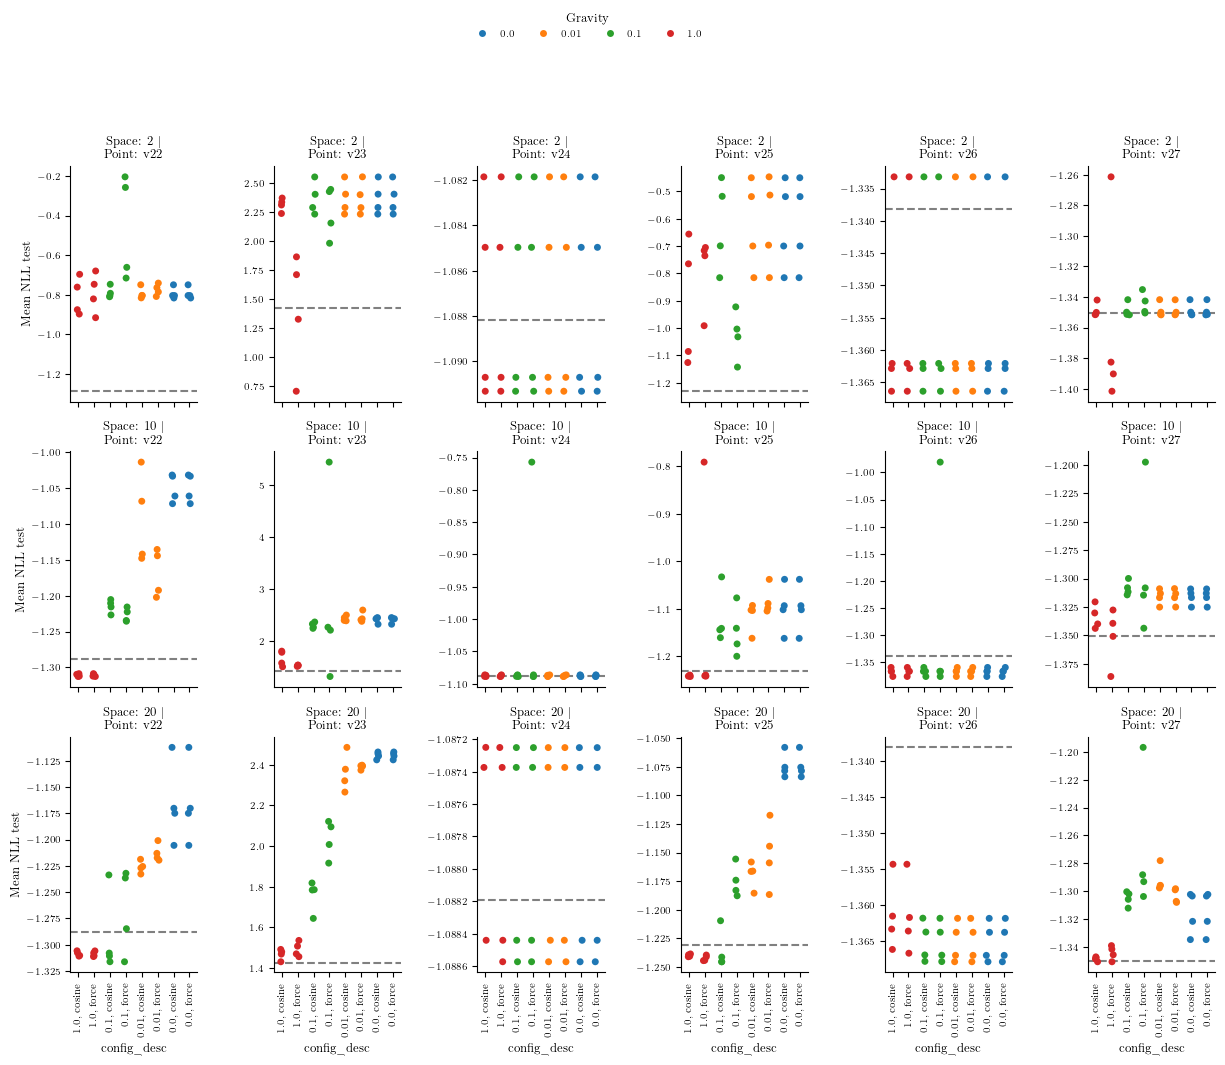

In [111]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='nll_test', x='config_desc',
                row='SubspaceDim', col='ParamsPath', kind='strip', hue='Gravity', sharey=False, height=3, aspect=0.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nPoint: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL test")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)
# Add horizontal lines for each ParamsPath column using init_point_performance_test
for ax, params_path in zip(g.axes[0].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[1].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[2].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')


#### Print validation performance

/tmp/ipykernel_730333/567595696.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity' 'Regularizer']


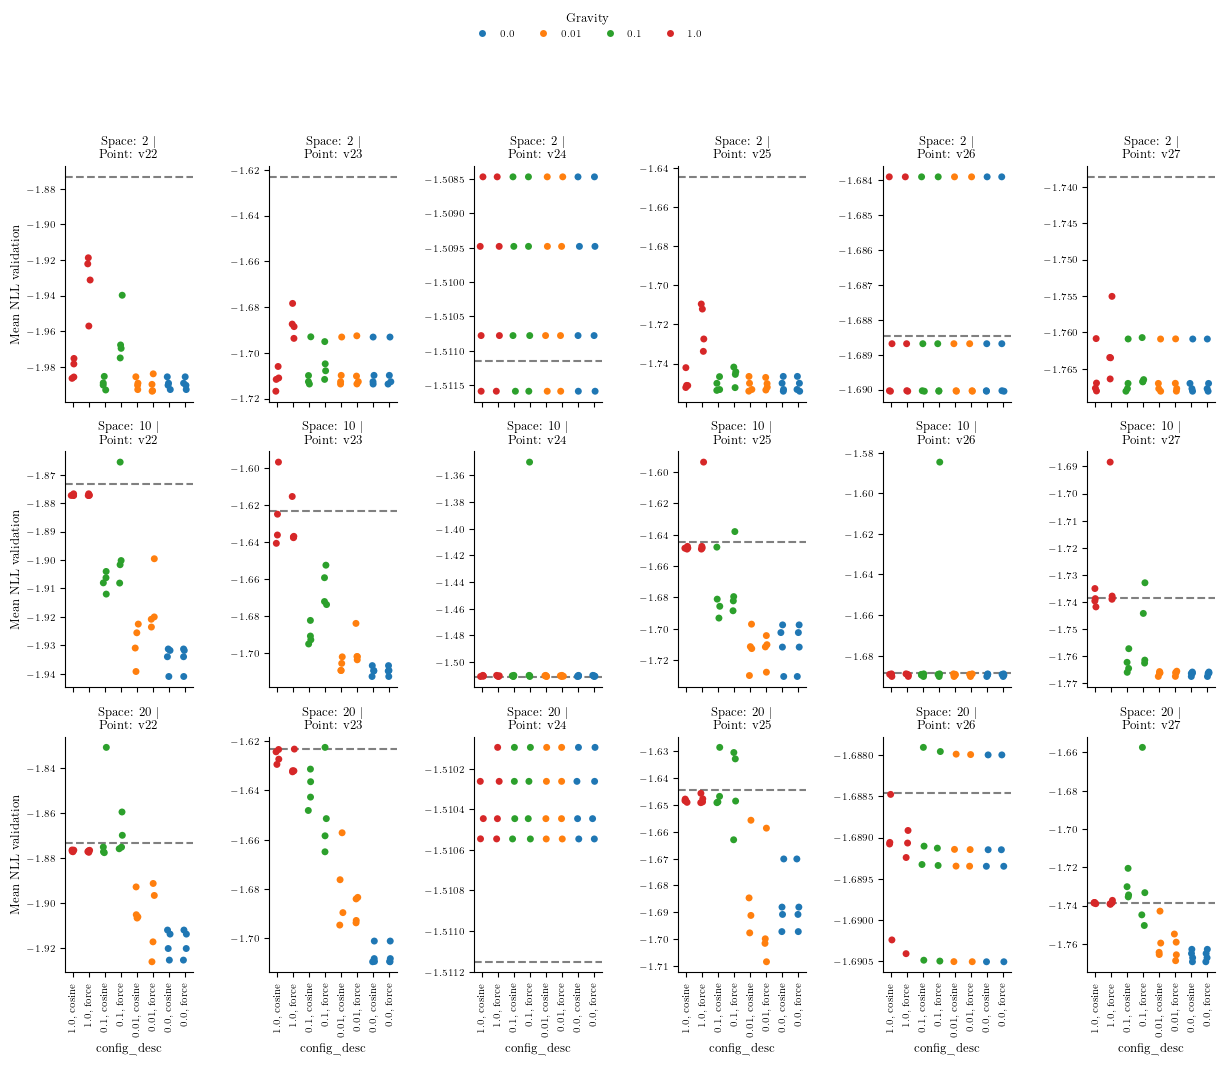

In [ ]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='nll_val', x='config_desc',
                row='SubspaceDim', col='ParamsPath', kind='strip', hue='Gravity', sharey=False, height=3, aspect=0.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nPoint: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL validation")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)
# Add horizontal lines for each ParamsPath column using init_point_performance_test
for ax, params_path in zip(g.axes[0].flat, g.col_names):
    ax.axhline(y=init_point_performance_valid[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[1].flat, g.col_names):
    ax.axhline(y=init_point_performance_valid[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[2].flat, g.col_names):
    ax.axhline(y=init_point_performance_valid[params_path], color='gray', linestyle='--', label='init point')


#### Length

In [112]:
df_clean.columns.values

array(['Id', 'SubspaceDim', 'Seed', 'Jitter', 'Gravity', 'WeightDecay',
       'RemoveInitialPermutation', 'Epochs', 'Lr', 'EnergyWeakening',
       'Regularizer', 'ParamsPath', 'mse_test', 'mse_test_last',
       'mse_val', 'mse_val_last', 'nll_test', 'nll_test_last', 'nll_val',
       'nll_val_last', 'length_best', 'length_last', 'cosine_similarity',
       'sample_std_best', 'sample_std_last', 'init_test_loss',
       'init_val_loss', 'config_desc'], dtype=object)

['Gravity' 'Regularizer']


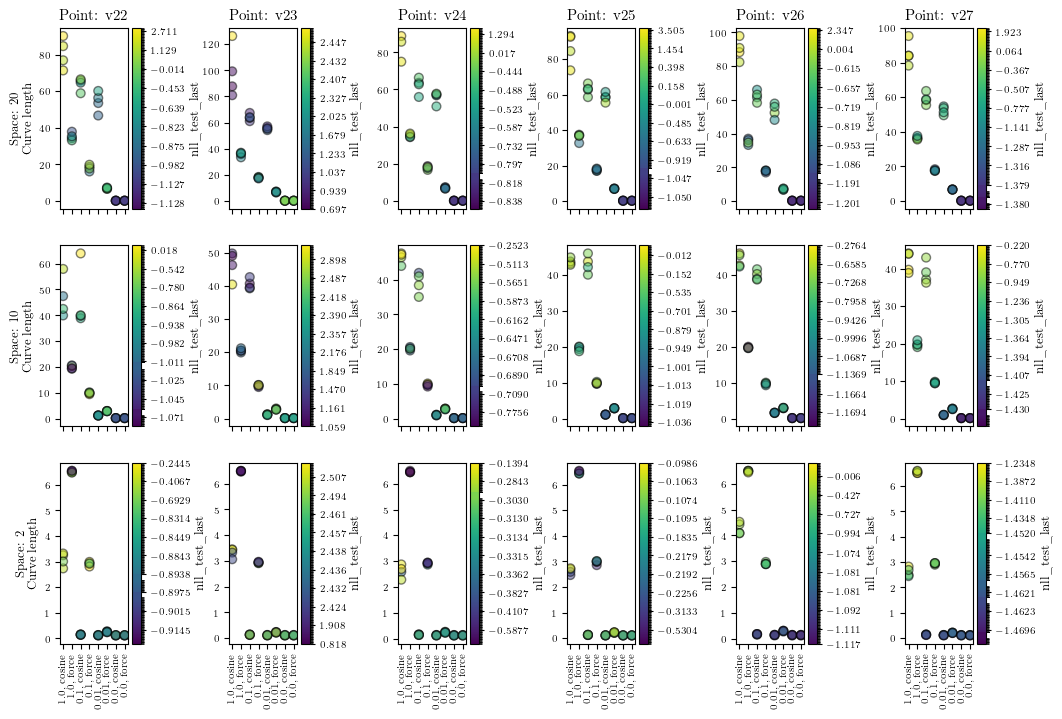

In [134]:
from matplotlib import colors
import seaborn as sns

df_subset = df_clean.copy()
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

# g = sns.catplot(
#     data=df_subset, y='length_last', x='config_desc',
#     row='SubspaceDim', col='ParamsPath', kind='strip',
#     sharey=False, height=3, aspect=0.7, palette='viridis', hue=None
# )
# g.set_titles(row_template='Space: {row_name}', col_template='\nPoint: {col_name}')
# g.tight_layout()
# g.set_ylabels("Mean NLL test")
# sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13))

rows = df_subset['SubspaceDim'].unique()
cols = df_subset['ParamsPath'].unique()
fig, axes = plt.subplots(
    nrows=len(rows),
    ncols=len(cols),
    figsize=(12, 8), sharex=True, sharey=False)

plt.subplots_adjust(wspace=1.)  # Increase horizontal space between columns

# Color points per subplot using their own colormap
for i, row in enumerate(rows):
    for j, col in enumerate(cols):
        ax = axes[i, j]
        subdata = df_subset[
            (df_subset['SubspaceDim'] == row) & (df_subset['ParamsPath'] == col)
        ]
        if not subdata.empty:
            # Quantile normalization for color mapping
            flat_mse = subdata['nll_test_last'].values.flatten()
            quantiles = np.quantile(flat_mse, np.linspace(0, 1, 255))
            norm = colors.BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)

            # norm = colors.Normalize(vmin=subdata['nll_test_last'].min(), vmax=subdata['nll_test_last'].max())

            cmap = plt.get_cmap('viridis')
            colors_ = cmap(norm(subdata['nll_test_last']))
            ax.scatter(
                subdata['config_desc'], subdata['length_last'],
                c=colors_, s=40, edgecolor='k', alpha=0.5
            )
            for label in ax.get_xticklabels():
                label.set_rotation(90)
            sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            plt.colorbar(sm, ax=ax, label='nll_test_last')

for ax, row in zip(axes[:,0].flat, rows):
    ax.set_ylabel(f"Space: {row}\nCurve length")


for ax, col in zip(axes[0,:].flat, cols):
    ax.set_title(f"Point: {col}")

print(desc_cols)


#### Functional diversity

['Gravity' 'Regularizer']


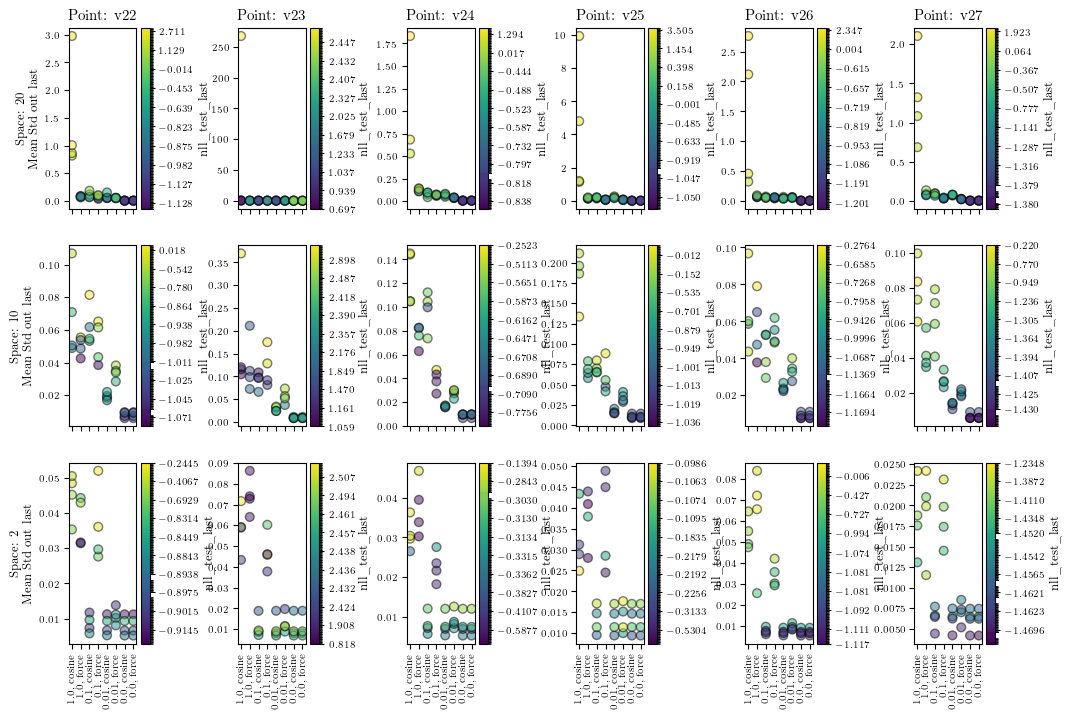

In [138]:
from matplotlib import colors
import seaborn as sns

df_subset = df_clean.copy()
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

# g = sns.catplot(
#     data=df_subset, y='length_last', x='config_desc',
#     row='SubspaceDim', col='ParamsPath', kind='strip',
#     sharey=False, height=3, aspect=0.7, palette='viridis', hue=None
# )
# g.set_titles(row_template='Space: {row_name}', col_template='\nPoint: {col_name}')
# g.tight_layout()
# g.set_ylabels("Mean NLL test")
# sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13))

rows = df_subset['SubspaceDim'].unique()
cols = df_subset['ParamsPath'].unique()
fig, axes = plt.subplots(
    nrows=len(rows),
    ncols=len(cols),
    figsize=(12, 8), sharex=True, sharey=False)

plt.subplots_adjust(wspace=1.)  # Increase horizontal space between columns

# Color points per subplot using their own colormap
for i, row in enumerate(rows):
    for j, col in enumerate(cols):
        ax = axes[i, j]
        subdata = df_subset[
            (df_subset['SubspaceDim'] == row) & (df_subset['ParamsPath'] == col)
        ]
        if not subdata.empty:
            # Quantile normalization for color mapping
            flat_mse = subdata['nll_test_last'].values.flatten()
            quantiles = np.quantile(flat_mse, np.linspace(0, 1, 255))
            norm = colors.BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)

            # norm = colors.Normalize(vmin=subdata['nll_test_last'].min(), vmax=subdata['nll_test_last'].max())

            cmap = plt.get_cmap('viridis')
            colors_ = cmap(norm(subdata['nll_test_last']))
            ax.scatter(
                subdata['config_desc'], subdata['sample_std_last'],
                c=colors_, s=40, edgecolor='k', alpha=0.5
            )
            for label in ax.get_xticklabels():
                label.set_rotation(90)
            sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            plt.colorbar(sm, ax=ax, label='nll_test_last')

for ax, row in zip(axes[:,0].flat, rows):
    ax.set_ylabel(f"Space: {row}\nMean Std out last")


for ax, col in zip(axes[0,:].flat, cols):
    ax.set_title(f"Point: {col}")

print(desc_cols)


#### Cosine similarity

['Gravity' 'Regularizer']


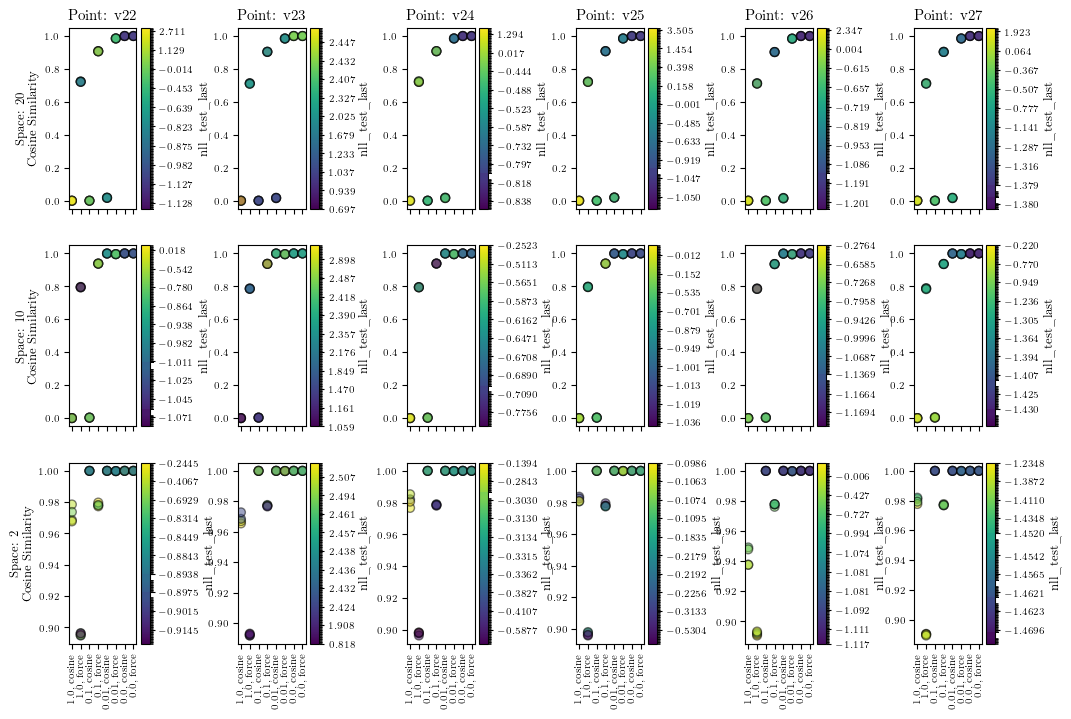

In [139]:
from matplotlib import colors
import seaborn as sns

df_subset = df_clean.copy()
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

# g = sns.catplot(
#     data=df_subset, y='length_last', x='config_desc',
#     row='SubspaceDim', col='ParamsPath', kind='strip',
#     sharey=False, height=3, aspect=0.7, palette='viridis', hue=None
# )
# g.set_titles(row_template='Space: {row_name}', col_template='\nPoint: {col_name}')
# g.tight_layout()
# g.set_ylabels("Mean NLL test")
# sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13))

rows = df_subset['SubspaceDim'].unique()
cols = df_subset['ParamsPath'].unique()
fig, axes = plt.subplots(
    nrows=len(rows),
    ncols=len(cols),
    figsize=(12, 8), sharex=True, sharey=False)

plt.subplots_adjust(wspace=1.)  # Increase horizontal space between columns

# Color points per subplot using their own colormap
for i, row in enumerate(rows):
    for j, col in enumerate(cols):
        ax = axes[i, j]
        subdata = df_subset[
            (df_subset['SubspaceDim'] == row) & (df_subset['ParamsPath'] == col)
        ]
        if not subdata.empty:
            # Quantile normalization for color mapping
            flat_mse = subdata['nll_test_last'].values.flatten()
            quantiles = np.quantile(flat_mse, np.linspace(0, 1, 255))
            norm = colors.BoundaryNorm(quantiles, ncolors=plt.get_cmap('viridis').N, clip=True)

            # norm = colors.Normalize(vmin=subdata['nll_test_last'].min(), vmax=subdata['nll_test_last'].max())

            cmap = plt.get_cmap('viridis')
            colors_ = cmap(norm(subdata['nll_test_last']))
            ax.scatter(
                subdata['config_desc'], subdata['cosine_similarity'],
                c=colors_, s=40, edgecolor='k', alpha=0.5
            )
            for label in ax.get_xticklabels():
                label.set_rotation(90)
            sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            plt.colorbar(sm, ax=ax, label='nll_test_last')

for ax, row in zip(axes[:,0].flat, rows):
    ax.set_ylabel(f"Space: {row}\nCosine Similarity")


for ax, col in zip(axes[0,:].flat, cols):
    ax.set_title(f"Point: {col}")

print(desc_cols)


#### std increase vs best

In [12]:
variable_idx

['SubspaceDim', 'Gravity', 'Regularizer', 'ParamsPath']

/tmp/ipykernel_753645/4161714482.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity' 'Regularizer']


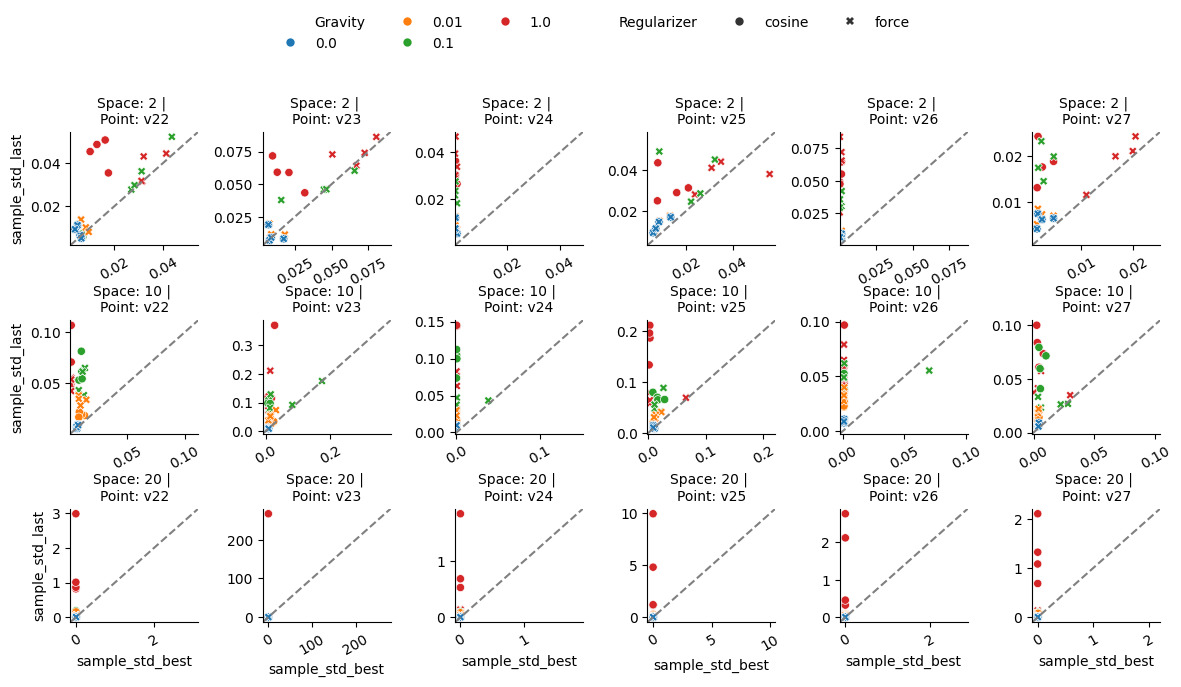

In [20]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'ParamsPath'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.relplot(data=df_subset, y='sample_std_last', x='sample_std_best',
                row='SubspaceDim', col='ParamsPath', kind='scatter', hue='Gravity', style="Regularizer", height=2, aspect=1., palette='tab10', facet_kws={'sharey': False, 'sharex': False})
g.set_titles(row_template='Space: {row_name}',
             col_template='\nPoint: {col_name}')
g.tight_layout()
# g.set_ylabels("Sample Std Last")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(30)

# # set x and y limits to the same range for each subplot while ke
for ax in g.axes.flatten():
    # Get current axis limits
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    # Set the same min/max for both axes (square plot)
    min_lim = min(x_min, y_min)
    max_lim = max(x_max, y_max)
    ax.set_xlim(min_lim, max_lim)
    ax.set_ylim(min_lim, max_lim)
    ax.plot([min_lim, max_lim], [min_lim, max_lim], color='gray', linestyle='--')  # Add a diagonal line for reference

print(desc_cols)



#### Compare vanilla curve vs point to curve

In [2]:
api = wandb.Api()
results = []
def path_to_seed(path):
    if path == "ddold/toyReg_PtoC/params:v22":
        return 0
    elif path == "ddold/toyReg_PtoC/params:v23":
        return 1
    elif path == "ddold/toyReg_PtoC/params:v24":
        return 2
    elif path == "ddold/toyReg_PtoC/params:v25":
        return 3
    elif path == "ddold/toyReg_PtoC/params:v26":
        return 4
    elif path == "ddold/toyReg_PtoC/params:v27":
        return 5
for s_id in ['kino2oun',]:
    t_bar = tqdm(api.sweep(f"ddold/toyReg_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            # art = run.used_artifacts()[1]
            # point_performance = art.logged_by().summary.get('nll_test_curve', np.nan)
            
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       SeedCurve=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       EnergyWeakening=run.config['curve_params']['energy_weakening'],
                       Regularizer=run.config['curve_params']['regularizer'],
                       ParamsPath=run.config['params_path'].replace("ddold/toyReg_PtoC/params:", ""),
                       SeedData=path_to_seed(run.config['params_path']),
                       mse_test=run.summary.get('mse_test_curve', np.nan),
                       mse_test_last=run.summary.get('mse_test_curve_last', np.nan),
                       mse_val=run.summary.get('mse_val_curve', np.nan),
                       mse_val_last=run.summary.get('mse_val_curve_last', np.nan),
                       nll_test=run.summary.get('nll_test_curve', np.nan),
                       nll_test_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val=run.summary.get('nll_val_curve', np.nan),
                       nll_val_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),
                       cosine_similarity=run.summary.get('cosine_similarity', np.nan),
                       sample_std_best=run.summary.get('Sample Std best', np.nan),
                       sample_std_last=run.summary.get('Sample Std last', np.nan),
                       init_test_loss=run.summary.get('init_test_loss', np.nan),
                       init_val_loss=run.summary.get('init_val_loss', np.nan),
                    #    init_point_performance=point_performance,
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df = pd.DataFrame(results)

# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
print("Runs with problems: \n", df[idx_config_with_nan]['Id'])
print()

df = df[~idx_config_with_nan]
df

Sweep id: kino2oun:   0%|          | 0/576 [00:00<?, ?it/s, hardy-sweep-547]        

Sweep id: kino2oun: 100%|██████████| 576/576 [00:01<00:00, 350.99it/s, legendary-sweep-1]      


Runs with problems: 
 11    fx6qa58n
Name: Id, dtype: object



,Id,SubspaceDim,SeedCurve,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,nll_test_last,nll_val,nll_val_last,length_best,length_last,cosine_similarity,sample_std_best,sample_std_last,init_test_loss,init_val_loss
0,2owgrada,20,4,1.000000e-08,1.0,0,False,2000,0.0003,1,...,1.219315,-1.876440,1.215595,0.025049,76.930573,0.000095,0.002601,0.818620,-1.288248,-1.873585
1,2n8zbg34,20,3,1.000000e-08,1.0,0,False,2000,0.0003,1,...,2.603427,-1.877008,2.602182,0.013384,71.383278,0.000030,0.002118,2.976406,-1.288249,-1.873585
2,hqbjf1vt,20,1,1.000000e-08,1.0,0,False,2000,0.0003,1,...,1.311521,-1.877210,1.306823,0.018350,84.674202,0.000045,0.002344,0.863977,-1.288248,-1.873585
3,a6cgka5h,20,0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,2.812646,-1.876504,2.870203,0.011866,90.203522,0.000048,0.001931,1.007576,-1.288248,-1.873585
4,t2n62wrb,20,4,1.000000e-08,1.0,0,False,2000,0.0003,1,...,0.794490,-1.623397,0.601701,0.013810,80.958641,0.000053,0.002778,0.421060,1.424805,-1.620949
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,fabu0pll,2,0,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.117079,-1.690048,-1.517040,0.002954,0.137031,0.999943,0.000553,0.006659,-1.338157,-1.686955
572,y8451gvc,2,4,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.451980,-1.760908,-1.698145,0.033495,0.119537,0.999956,0.004710,0.006474,-1.350388,-1.738296
573,tirm7ipr,2,3,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.469655,-1.767003,-1.701199,0.021035,0.114637,0.999960,0.001535,0.004179,-1.350388,-1.738296
574,jpliaqvw,2,1,1.000000e-08,0.0,0,False,2000,0.0003,1,...,-1.456488,-1.768074,-1.688492,0.032722,0.118290,0.999957,0.001694,0.007441,-1.350388,-1.738296


In [3]:
api = wandb.Api()
results = []
for s_id in ['i33b707j']:
    t_bar = tqdm(api.sweep(f"ddold/toyReg_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            # art = run.used_artifacts()[1]
            # point_performance = art.logged_by().summary.get('nll_test_curve', np.nan)
            
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       SeedData=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       EnergyWeakening=run.config['curve_params']['energy_weakening'],
                       Regularizer=run.config['curve_params']['regularizer'],
                       mse_test=run.summary.get('mse_test_curve', np.nan),
                       mse_test_last=run.summary.get('mse_test_curve_last', np.nan),
                       mse_val=run.summary.get('mse_val_curve', np.nan),
                       mse_val_last=run.summary.get('mse_val_curve_last', np.nan),
                       nll_test=run.summary.get('nll_test_curve', np.nan),
                       nll_test_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val=run.summary.get('nll_val_curve', np.nan),
                       nll_val_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),

                       mse_test_min=run.summary.get('mse_test_curve_min', np.nan),
                       mse_test_last_min=run.summary.get('mse_test_curve_last_min', np.nan),
                       mse_val_min=run.summary.get('mse_val_curve_min', np.nan),
                       mse_val_last_min=run.summary.get('mse_val_curve_last_min', np.nan),
                       nll_test_min=run.summary.get('nll_test_curve_min', np.nan),
                       nll_test_last_min=run.summary.get('nll_test_curve_last_min', np.nan),
                       nll_val_min=run.summary.get('nll_val_curve_min', np.nan),
                       nll_val_last_min=run.summary.get('nll_val_curve_last_min', np.nan),

                       cosine_similarity=run.summary.get('cosine_similarity', np.nan),
                       sample_std_best=run.summary.get('Sample Std best', np.nan),
                       sample_std_last=run.summary.get('Sample Std last', np.nan),
                    #    init_point_performance=point_performance,
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df_vanilla = pd.DataFrame(results)
# runs with problems
idx_config_with_nan = df_vanilla.isnull().values.any(axis=1)
print("Runs with problems: \n", df_vanilla[idx_config_with_nan]['Id'])
print()

df_vanilla = df_vanilla[~idx_config_with_nan]

df_vanilla


Sweep id: i33b707j:   0%|          | 0/144 [00:00<?, ?it/s, breezy-sweep-125]       

Sweep id: i33b707j: 100%|██████████| 144/144 [00:00<00:00, 441.06it/s, vital-sweep-1]     

Runs with problems: 
 Series([], Name: Id, dtype: object)



,Id,SubspaceDim,SeedData,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,mse_test_last_min,mse_val_min,mse_val_last_min,nll_test_min,nll_test_last_min,nll_val_min,nll_val_last_min,cosine_similarity,sample_std_best,sample_std_last
0,8xik05k0,20,5,1.000000e-08,1.0,0,False,2000,0.0003,1,...,0.005925,0.002844,0.002169,-0.892206,-0.902166,-0.971344,-0.999676,3.748707e-07,0.036204,0.038386
1,mrk1wvws,20,4,1.000000e-08,1.0,0,False,2000,0.0003,1,...,0.008005,0.003011,0.002978,-0.943875,-0.990495,-1.349803,-1.347932,1.314637e-06,0.023462,0.022538
2,pz53epyq,20,3,1.000000e-08,1.0,0,False,2000,0.0003,1,...,0.041539,0.020058,0.019785,0.019710,0.025968,-0.061217,-0.066336,5.692244e-07,0.062854,0.064280
3,goiaco92,20,2,1.000000e-08,1.0,0,False,2000,0.0003,1,...,0.012384,0.010061,0.008188,-0.602227,-0.681538,-0.724151,-0.766709,-1.152357e-07,0.032385,0.034363
4,u7del1oc,20,0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,0.004171,0.002974,0.002530,-1.114850,-1.137851,-1.185066,-1.210429,5.446730e-07,0.022757,0.026583
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,cjjfrfvs,2,4,1.000000e-08,0.0,0,False,2000,0.0003,1,...,0.002880,0.001639,0.001857,-1.427304,-1.456015,-1.770516,-1.725445,5.208509e-02,0.021707,0.021910
140,yq8ksb5c,2,3,1.000000e-08,0.0,0,False,2000,0.0003,1,...,0.003974,0.001235,0.001712,-1.337451,-1.342098,-1.722705,-1.658740,4.077552e-02,0.046800,0.044951
141,fp22vght,2,2,1.000000e-08,0.0,0,False,2000,0.0003,1,...,0.007143,0.002566,0.003049,-0.768182,-0.821538,-1.543984,-1.477324,-3.090188e-03,0.033884,0.026468
142,n57tth1b,2,1,1.000000e-08,0.0,0,False,2000,0.0003,1,...,0.015641,0.001302,0.001465,-0.391213,0.349450,-1.725750,-1.703128,4.943187e-02,0.030510,0.034672


In [4]:
df['Mode'] = 'PointToCurve'
df_vanilla['Mode'] = 'Curve'
df = pd.concat([df, df_vanilla], ignore_index=True)
df.drop(columns=['ParamsPath'], inplace=True)  # remove seed for data, since it is not used in the paper
df

,Id,SubspaceDim,SeedCurve,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,EnergyWeakening,...,init_val_loss,Mode,mse_test_min,mse_test_last_min,mse_val_min,mse_val_last_min,nll_test_min,nll_test_last_min,nll_val_min,nll_val_last_min
0,2owgrada,20,4.0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,-1.873585,PointToCurve,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2n8zbg34,20,3.0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,-1.873585,PointToCurve,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,hqbjf1vt,20,1.0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,-1.873585,PointToCurve,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,a6cgka5h,20,0.0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,-1.873585,PointToCurve,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,t2n62wrb,20,4.0,1.000000e-08,1.0,0,False,2000,0.0003,1,...,-1.620949,PointToCurve,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
714,cjjfrfvs,2,NaN,1.000000e-08,0.0,0,False,2000,0.0003,1,...,NaN,Curve,0.003122,0.002880,0.001639,0.001857,-1.427304,-1.456015,-1.770516,-1.725445
715,yq8ksb5c,2,NaN,1.000000e-08,0.0,0,False,2000,0.0003,1,...,NaN,Curve,0.004011,0.003974,0.001235,0.001712,-1.337451,-1.342098,-1.722705,-1.658740
716,fp22vght,2,NaN,1.000000e-08,0.0,0,False,2000,0.0003,1,...,NaN,Curve,0.007912,0.007143,0.002566,0.003049,-0.768182,-0.821538,-1.543984,-1.477324
717,n57tth1b,2,NaN,1.000000e-08,0.0,0,False,2000,0.0003,1,...,NaN,Curve,0.010550,0.015641,0.001302,0.001465,-0.391213,0.349450,-1.725750,-1.703128


In [5]:
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)

print("Unique configuartions: ")
variable_idx = []
for c in df.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and (c != 'SeedCurve'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
variable_idx

Unique configuartions: 
SubspaceDim [20 10  2]
SeedCurve [ 4.  3.  1.  0. nan]
Jitter [1.e-08]
Gravity [1.   0.1  0.01 0.  ]
WeightDecay [0]
RemoveInitialPermutation [False]
Epochs [2000]
Lr [0.0003]
EnergyWeakening [1]
Regularizer ['cosine' 'force']
SeedData [0 1 2 3 4 5]
Mode ['PointToCurve' 'Curve']

Experiment differs in ['SubspaceDim', 'Gravity', 'Regularizer', 'SeedData', 'Mode'] configs


['SubspaceDim', 'Gravity', 'Regularizer', 'SeedData', 'Mode']

['Regularizer' 'SeedData']


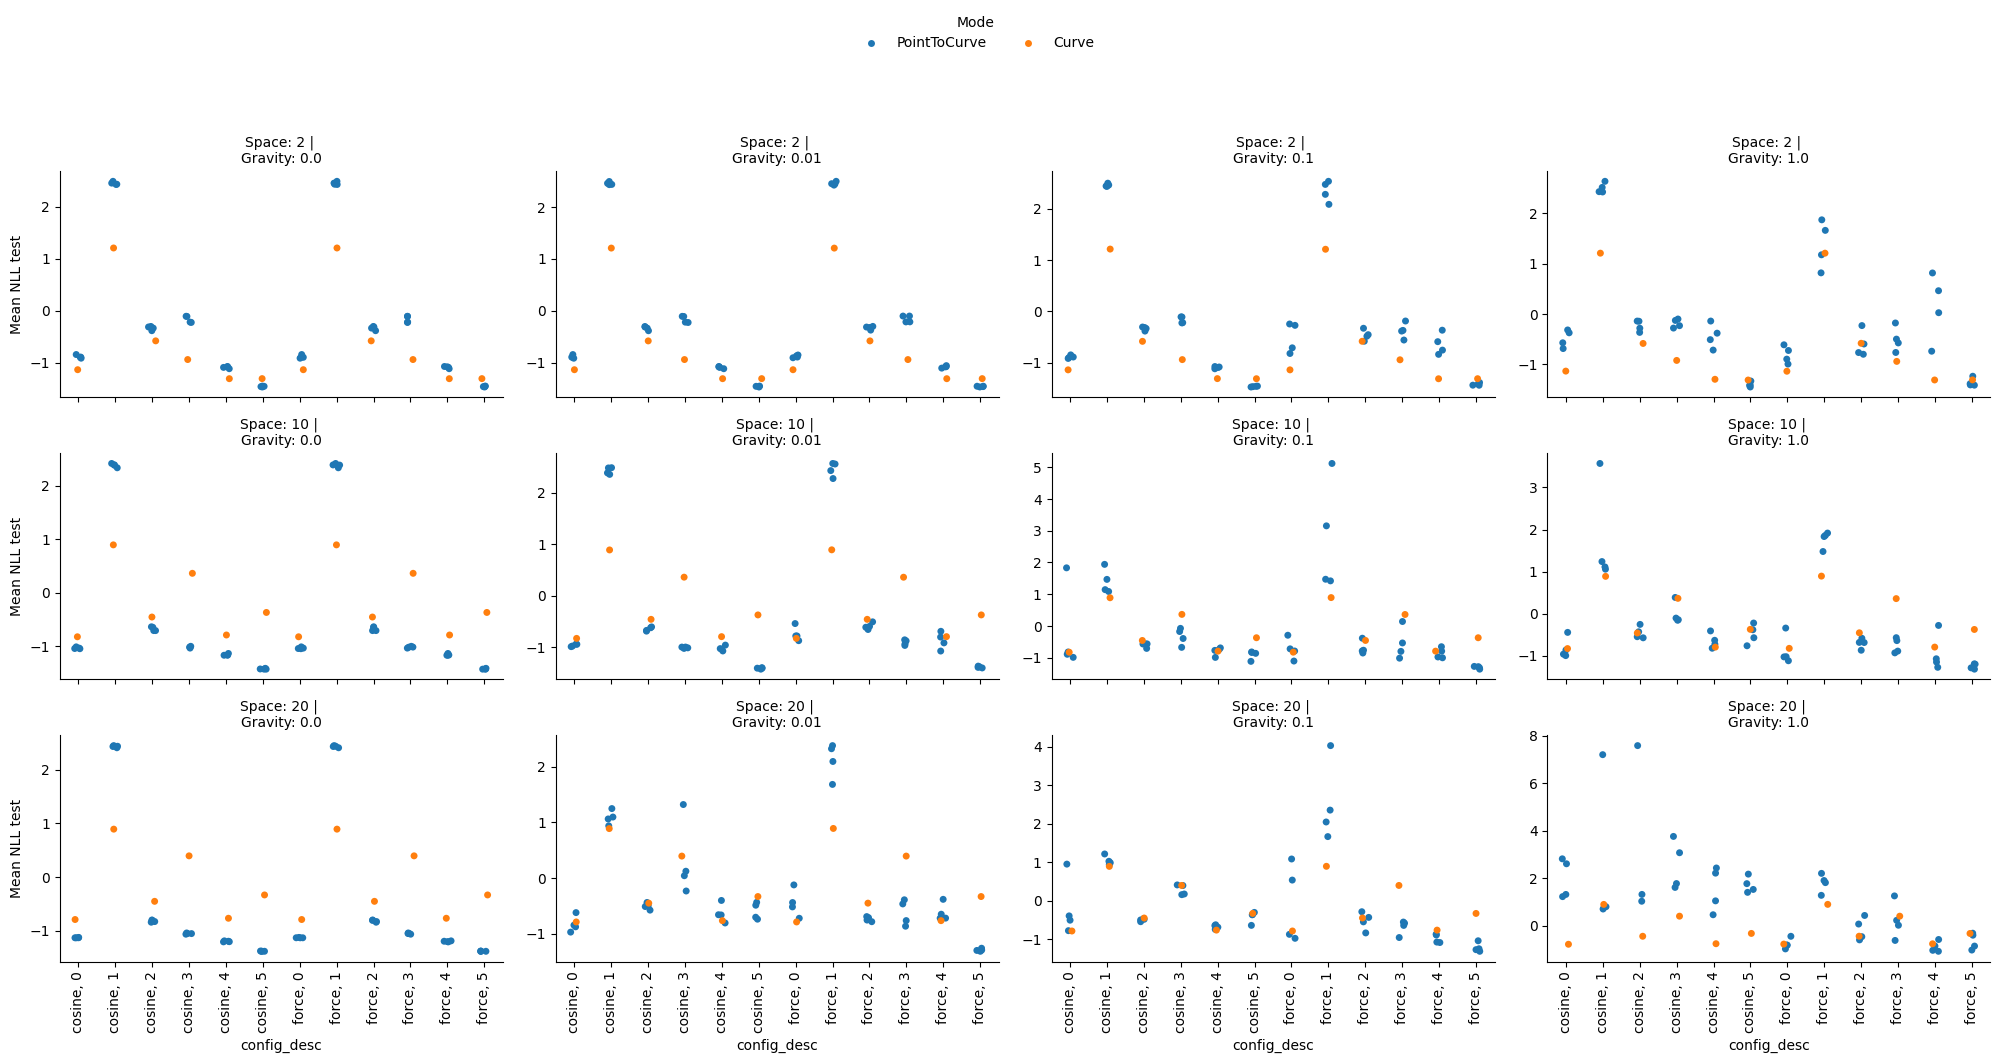

In [6]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df.copy()
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Mode', 'Gravity'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='nll_test_last', x='config_desc',
                row='SubspaceDim', col='Gravity', kind='strip', hue='Mode', sharey=False, height=3, aspect=1.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nGravity: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL test")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)
# Add horizontal lines for each ParamsPath column using init_point_performance_test
# for ax, params_path in zip(g.axes[0].flat, g.col_names):
#     ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
# for ax, params_path in zip(g.axes[1].flat, g.col_names):
#     ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
# for ax, params_path in zip(g.axes[2].flat, g.col_names):
    # ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')


['SeedData']


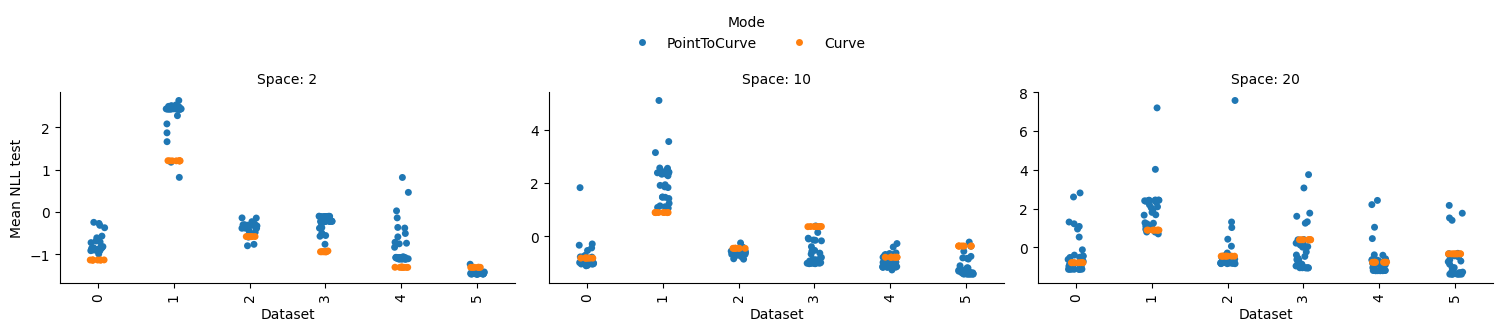

In [8]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df.copy()
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Mode', 'Gravity', 'Regularizer'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='nll_test_last', x='config_desc',
                col='SubspaceDim', kind='strip', hue='Mode', sharey=False, height=3, aspect=1.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL test")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)
g.set_xlabels("Dataset")


In [8]:
df_subset = df.copy()
df_subset.set_index(['SubspaceDim', 'Gravity', 'Regularizer', 'SeedData'], inplace=True)
# Melt the table to long format for all value_ids, keeping 'Mode' as a variable
# Pivot to wide format, but flatten the columns so there is no MultiIndex
pivoted = df_subset.pivot_table(
    index=['SubspaceDim', 'Gravity', 'Regularizer', 'SeedData'],
    columns='Mode',
    values=value_ids
)
pivoted.columns = [f"{val}_{mode}" for val, mode in pivoted.columns]
pivoted.reset_index(inplace=True)
pivoted

,SubspaceDim,Gravity,Regularizer,SeedData,cosine_similarity_Curve,cosine_similarity_PointToCurve,init_test_loss_PointToCurve,init_val_loss_PointToCurve,length_best_Curve,length_best_PointToCurve,...,nll_val_Curve,nll_val_PointToCurve,nll_val_last_Curve,nll_val_last_PointToCurve,nll_val_last_min_Curve,nll_val_min_Curve,sample_std_best_Curve,sample_std_best_PointToCurve,sample_std_last_Curve,sample_std_last_PointToCurve
0,2,0.0,cosine,0,0.060764,0.999957,-1.288249,-1.873585,19.008133,0.116207,...,-1.892049,-1.989583,-1.874574,-1.942764,-1.939707,-1.940589,0.019381,0.005243,0.020331,0.008057
1,2,0.0,cosine,1,0.049432,0.999964,1.424804,-1.620949,19.546297,0.079075,...,-1.685218,-1.707317,-1.626351,-1.682455,-1.703128,-1.725750,0.030510,0.010196,0.034672,0.010662
2,2,0.0,cosine,2,-0.003090,0.999955,-1.088190,-1.510316,20.175034,0.001745,...,-1.474530,-1.510080,-1.440880,-1.378725,-1.477323,-1.543984,0.033884,0.000444,0.026468,0.007897
3,2,0.0,cosine,3,0.040776,0.999964,-1.231072,-1.645939,19.457623,0.102919,...,-1.656054,-1.750997,-1.550321,-1.670850,-1.658740,-1.722705,0.046800,0.008593,0.044951,0.013144
4,2,0.0,cosine,4,0.052085,0.999946,-1.338157,-1.686955,19.645140,0.004222,...,-1.631203,-1.688169,-1.591381,-1.537853,-1.725445,-1.770517,0.021707,0.001069,0.021910,0.007230
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,20,1.0,force,1,0.002759,0.711721,1.424804,-1.620949,47.051338,0.054316,...,-0.172772,-1.629938,-0.183195,-0.991596,-0.512909,-0.438984,0.057061,0.006446,0.056187,0.135881
140,20,1.0,force,2,0.000270,0.722564,-1.088190,-1.510316,47.142708,0.001180,...,-0.453618,-1.510337,-0.457378,-1.043105,-0.746221,-0.728579,0.034936,0.000178,0.035938,0.125045
141,20,1.0,force,3,-0.005526,0.722152,-1.231072,-1.645939,47.584332,0.026057,...,0.327835,-1.647867,0.324070,-0.883448,-0.048418,-0.064362,0.065469,0.004062,0.067179,0.158175
142,20,1.0,force,4,-0.005485,0.711933,-1.338157,-1.686955,46.991814,0.014580,...,-1.230670,-1.689408,-1.227750,-1.225198,-1.362050,-1.365689,0.023965,0.001608,0.022754,0.076428


In [38]:
handles, labels = g.axes[0,0].get_legend_handles_labels()
labels

['Gravity',
 '0.0',
 '0.01',
 '0.1',
 '1.0',
 'SeedData',
 '0',
 '1',
 '2',
 '3',
 '4',
 '5',
 'Regularizer',
 'cosine',
 'force']

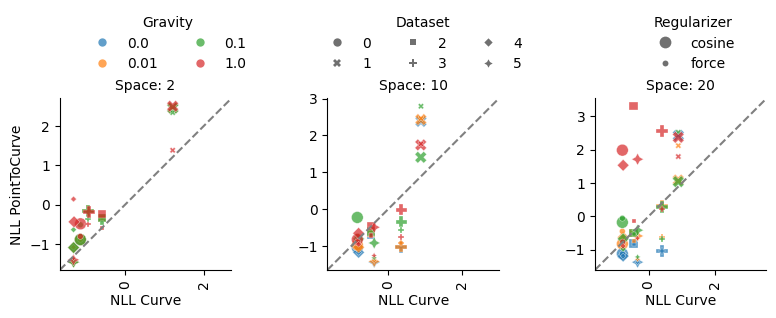

In [71]:
g = sns.relplot(data=pivoted, y='nll_test_last_PointToCurve', x='nll_test_last_Curve',
                col='SubspaceDim', kind='scatter', hue='Gravity', style="SeedData", size="Regularizer", height=3, aspect=1, palette='tab10', alpha=0.7, facet_kws={'sharey': False, 'sharex': False})
g.set_titles(row_template='Space: {row_name}',
             col_template='\nSpace: {col_name}')
# g.set(ylim=(0., 22.96))
# sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=8)
handles, labels = g.axes[0,0].get_legend_handles_labels()
# remove default legend
g._legend.remove()
g.add_legend(title='Gravity', handles=handles[1:5], labels=labels[1:5], loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=2)
g.add_legend(title='Dataset', handles=handles[6:12], labels=labels[6:12], loc='upper center', bbox_to_anchor=(.47, 1.15), ncol=3)
g.add_legend(title='Regularizer', handles=handles[13:], labels=labels[13:], loc='upper center', bbox_to_anchor=(.65, 1.15), ncol=1)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.subplots_adjust(wspace=-.6)  # Adjust horizontal space between columns and vertical space between rows
g.tight_layout()

g.set_xlabels("NLL Curve")
g.set_ylabels("NLL PointToCurve")

for ax in g.axes.flatten():
    # Get current axis limits
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    # Set the same min/max for both axes (square plot)
    min_lim = min(x_min, y_min)
    max_lim = max(x_max, y_max)
    ax.set_xlim(min_lim, max_lim)
    ax.set_ylim(min_lim, max_lim)
    ax.plot([min_lim, max_lim], [min_lim, max_lim], color='gray', linestyle='--')  # Add a diagonal line for reference

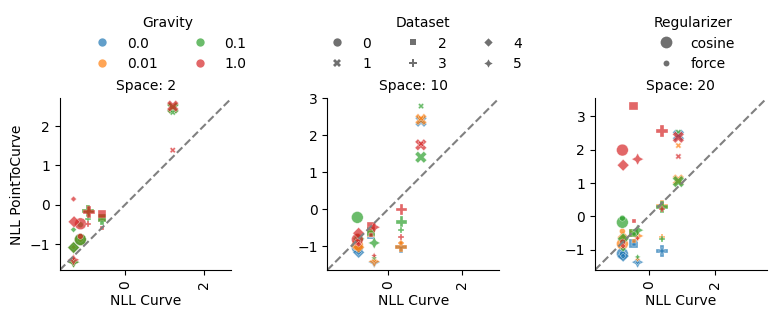

In [72]:
g = sns.relplot(data=pivoted, y='nll_test_last_PointToCurve', x='nll_test_last_Curve',
                col='SubspaceDim', kind='scatter', hue='Gravity', style="SeedData", size="Regularizer", height=3, aspect=1, palette='tab10', alpha=0.7, facet_kws={'sharey': False, 'sharex': False})
g.set_titles(row_template='Space: {row_name}',
             col_template='\nSpace: {col_name}')

for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

g.set_xlabels("NLL Curve")
g.set_ylabels("NLL PointToCurve")

handles, labels = g.axes[0,0].get_legend_handles_labels()
# remove default legend
g._legend.remove()
g.add_legend(title='Gravity', handles=handles[1:5], labels=labels[1:5], loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=2)
g.add_legend(title='Dataset', handles=handles[6:12], labels=labels[6:12], loc='upper center', bbox_to_anchor=(.47, 1.15), ncol=3)
g.add_legend(title='Regularizer', handles=handles[13:], labels=labels[13:], loc='upper center', bbox_to_anchor=(.65, 1.15), ncol=1)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.subplots_adjust(wspace=-.6)  # Adjust horizontal space between columns and vertical space between rows
g.tight_layout()

for ax in g.axes.flatten():
    # Get current axis limits
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    # Set the same min/max for both axes (square plot)
    min_lim = min(x_min, y_min)
    max_lim = max(x_max, y_max)
    ax.set_xlim(min_lim, max_lim)
    ax.set_ylim(min_lim, max_lim)
    ax.plot([min_lim, max_lim], [min_lim, max_lim], color='gray', linestyle='--')  # Add a diagonal line for reference


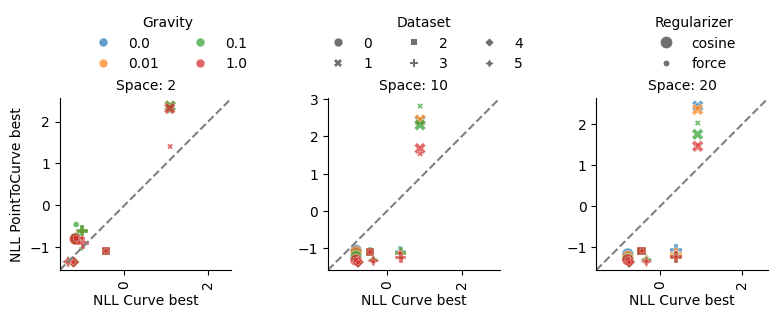

In [73]:
g = sns.relplot(data=pivoted, y='nll_test_PointToCurve', x='nll_test_Curve',
                col='SubspaceDim', kind='scatter',hue='Gravity', style="SeedData", size="Regularizer", height=3, aspect=1, palette='tab10', alpha=0.7, facet_kws={'sharey': False, 'sharex': False})
g.set_titles(row_template='Space: {row_name}',
             col_template='\nSpace: {col_name}')

for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

g.set_xlabels("NLL Curve best")
g.set_ylabels("NLL PointToCurve best")

handles, labels = g.axes[0,0].get_legend_handles_labels()
# remove default legend
g._legend.remove()
g.add_legend(title='Gravity', handles=handles[1:5], labels=labels[1:5], loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=2)
g.add_legend(title='Dataset', handles=handles[6:12], labels=labels[6:12], loc='upper center', bbox_to_anchor=(.47, 1.15), ncol=3)
g.add_legend(title='Regularizer', handles=handles[13:], labels=labels[13:], loc='upper center', bbox_to_anchor=(.65, 1.15), ncol=1)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.subplots_adjust(wspace=-.6)  # Adjust horizontal space between columns and vertical space between rows
g.tight_layout()

for ax in g.axes.flatten():
    # Get current axis limits
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    # Set the same min/max for both axes (square plot)
    min_lim = min(x_min, y_min)
    max_lim = max(x_max, y_max)
    ax.set_xlim(min_lim, max_lim)
    ax.set_ylim(min_lim, max_lim)
    ax.plot([min_lim, max_lim], [min_lim, max_lim], color='gray', linestyle='--')  # Add a diagonal line for reference


In [25]:
pivoted.columns.values

array(['SubspaceDim', 'Gravity', 'Regularizer', 'SeedData',
       'cosine_similarity_Curve', 'cosine_similarity_PointToCurve',
       'init_test_loss_PointToCurve', 'init_val_loss_PointToCurve',
       'length_best_Curve', 'length_best_PointToCurve',
       'length_last_Curve', 'length_last_PointToCurve', 'mse_test_Curve',
       'mse_test_PointToCurve', 'mse_test_last_Curve',
       'mse_test_last_PointToCurve', 'mse_val_Curve',
       'mse_val_PointToCurve', 'mse_val_last_Curve',
       'mse_val_last_PointToCurve', 'nll_test_Curve',
       'nll_test_PointToCurve', 'nll_test_last_Curve',
       'nll_test_last_PointToCurve', 'nll_val_Curve',
       'nll_val_PointToCurve', 'nll_val_last_Curve',
       'nll_val_last_PointToCurve', 'sample_std_best_Curve',
       'sample_std_best_PointToCurve', 'sample_std_last_Curve',
       'sample_std_last_PointToCurve'], dtype=object)

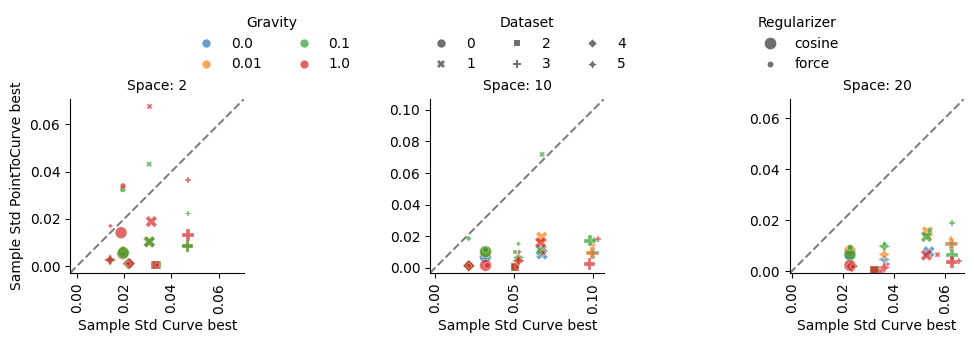

In [74]:
g = sns.relplot(data=pivoted, y='sample_std_best_PointToCurve', x='sample_std_best_Curve',
                col='SubspaceDim', kind='scatter',hue='Gravity', style="SeedData", size="Regularizer", height=3, aspect=1, palette='tab10', alpha=0.7, facet_kws={'sharey': False, 'sharex': False})
g.set_titles(row_template='Space: {row_name}',
             col_template='\nSpace: {col_name}')

for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

g.set_xlabels("Sample Std Curve best")
g.set_ylabels("Sample Std PointToCurve best")

handles, labels = g.axes[0,0].get_legend_handles_labels()
# remove default legend
g._legend.remove()
g.add_legend(title='Gravity', handles=handles[1:5], labels=labels[1:5], loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=2)
g.add_legend(title='Dataset', handles=handles[6:12], labels=labels[6:12], loc='upper center', bbox_to_anchor=(.47, 1.15), ncol=3)
g.add_legend(title='Regularizer', handles=handles[13:], labels=labels[13:], loc='upper center', bbox_to_anchor=(.65, 1.15), ncol=1)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.subplots_adjust(wspace=-.6)  # Adjust horizontal space between columns and vertical space between rows
g.tight_layout()

for ax in g.axes.flatten():
    # Get current axis limits
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    # Set the same min/max for both axes (square plot)
    min_lim = min(x_min, y_min)
    max_lim = max(x_max, y_max)
    ax.set_xlim(min_lim, max_lim)
    ax.set_ylim(min_lim, max_lim)
    ax.plot([min_lim, max_lim], [min_lim, max_lim], color='gray', linestyle='--')  # Add a diagonal line for reference


(-0.5, 5.0)

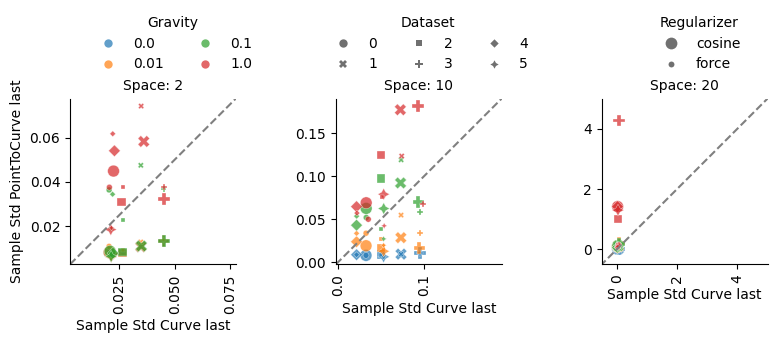

In [79]:
g = sns.relplot(data=pivoted, y='sample_std_last_PointToCurve', x='sample_std_last_Curve',
                col='SubspaceDim', kind='scatter',hue='Gravity', style="SeedData", size="Regularizer", height=3, aspect=1, palette='tab10', alpha=0.7, facet_kws={'sharey': False, 'sharex': False})
g.set_titles(row_template='Space: {row_name}',
             col_template='\nSpace: {col_name}')

for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

g.set_xlabels("Sample Std Curve last")
g.set_ylabels("Sample Std PointToCurve last")

handles, labels = g.axes[0,0].get_legend_handles_labels()
# remove default legend
g._legend.remove()
g.add_legend(title='Gravity', handles=handles[1:5], labels=labels[1:5], loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=2)
g.add_legend(title='Dataset', handles=handles[6:12], labels=labels[6:12], loc='upper center', bbox_to_anchor=(.47, 1.15), ncol=3)
g.add_legend(title='Regularizer', handles=handles[13:], labels=labels[13:], loc='upper center', bbox_to_anchor=(.65, 1.15), ncol=1)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.subplots_adjust(wspace=-.6)  # Adjust horizontal space between columns and vertical space between rows
g.tight_layout()

for ax in g.axes.flatten():
    # Get current axis limits
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    # Set the same min/max for both axes (square plot)
    min_lim = min(x_min, y_min)
    max_lim = max(x_max, y_max)
    ax.set_xlim(min_lim, max_lim)
    ax.set_ylim(min_lim, max_lim)
    ax.plot([min_lim, max_lim], [min_lim, max_lim], color='gray', linestyle='--')  # Add a diagonal line for reference

g.axes[0,2].set_xlim(-0.5, 5.)
g.axes[0,2].set_ylim(-0.5, 5.)


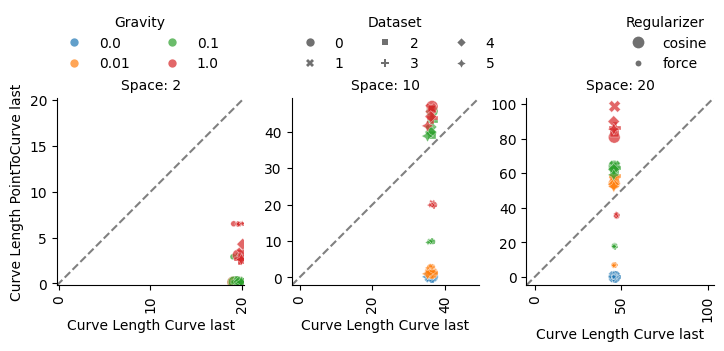

In [76]:
g = sns.relplot(data=pivoted, y='length_last_PointToCurve', x='length_last_Curve',
                col='SubspaceDim', kind='scatter',hue='Gravity', style="SeedData", size="Regularizer", height=3, aspect=1, palette='tab10', alpha=0.7, facet_kws={'sharey': False, 'sharex': False})
g.set_titles(row_template='Space: {row_name}',
             col_template='\nSpace: {col_name}')

for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

g.set_xlabels("Curve Length Curve last")
g.set_ylabels("Curve Length PointToCurve last")

handles, labels = g.axes[0,0].get_legend_handles_labels()
# remove default legend
g._legend.remove()
g.add_legend(title='Gravity', handles=handles[1:5], labels=labels[1:5], loc='upper center', bbox_to_anchor=(0.3, 1.15), ncol=2)
g.add_legend(title='Dataset', handles=handles[6:12], labels=labels[6:12], loc='upper center', bbox_to_anchor=(.47, 1.15), ncol=3)
g.add_legend(title='Regularizer', handles=handles[13:], labels=labels[13:], loc='upper center', bbox_to_anchor=(.65, 1.15), ncol=1)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.subplots_adjust(wspace=-.6)  # Adjust horizontal space between columns and vertical space between rows
g.tight_layout()

for ax in g.axes.flatten():
    # Get current axis limits
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    # Set the same min/max for both axes (square plot)
    min_lim = min(x_min, y_min)
    max_lim = max(x_max, y_max)
    ax.set_xlim(min_lim, max_lim)
    ax.set_ylim(min_lim, max_lim)
    ax.plot([min_lim, max_lim], [min_lim, max_lim], color='gray', linestyle='--')  # Add a diagonal line for reference


In [53]:
init_point_performance_test = {}
init_point_performance_valid = {}
init_point_performance_mse_test = {}
for run in api.runs("ddold/toyReg_PtoC"):
    if "single" in run.name:
        id_ = run.logged_artifacts()[1].name.split(':')[1].replace("v", "")
        id_ = int(id_) - 22  # Adjusting the id to match the original code's logic
        init_point_performance_test[id_] = run.summary['nll_test_curve']
        init_point_performance_valid[id_] = run.summary['nll_val_curve']
        init_point_performance_mse_test[id_] = run.summary['mse_test_curve']
init_point_performance_test

{0: -1.2882485389709473,
 1: 1.4248046875,
 2: -1.0881903171539309,
 3: -1.2310723066329956,
 4: -1.338157057762146,
 5: -1.350387692451477}

['Gravity' 'Regularizer']


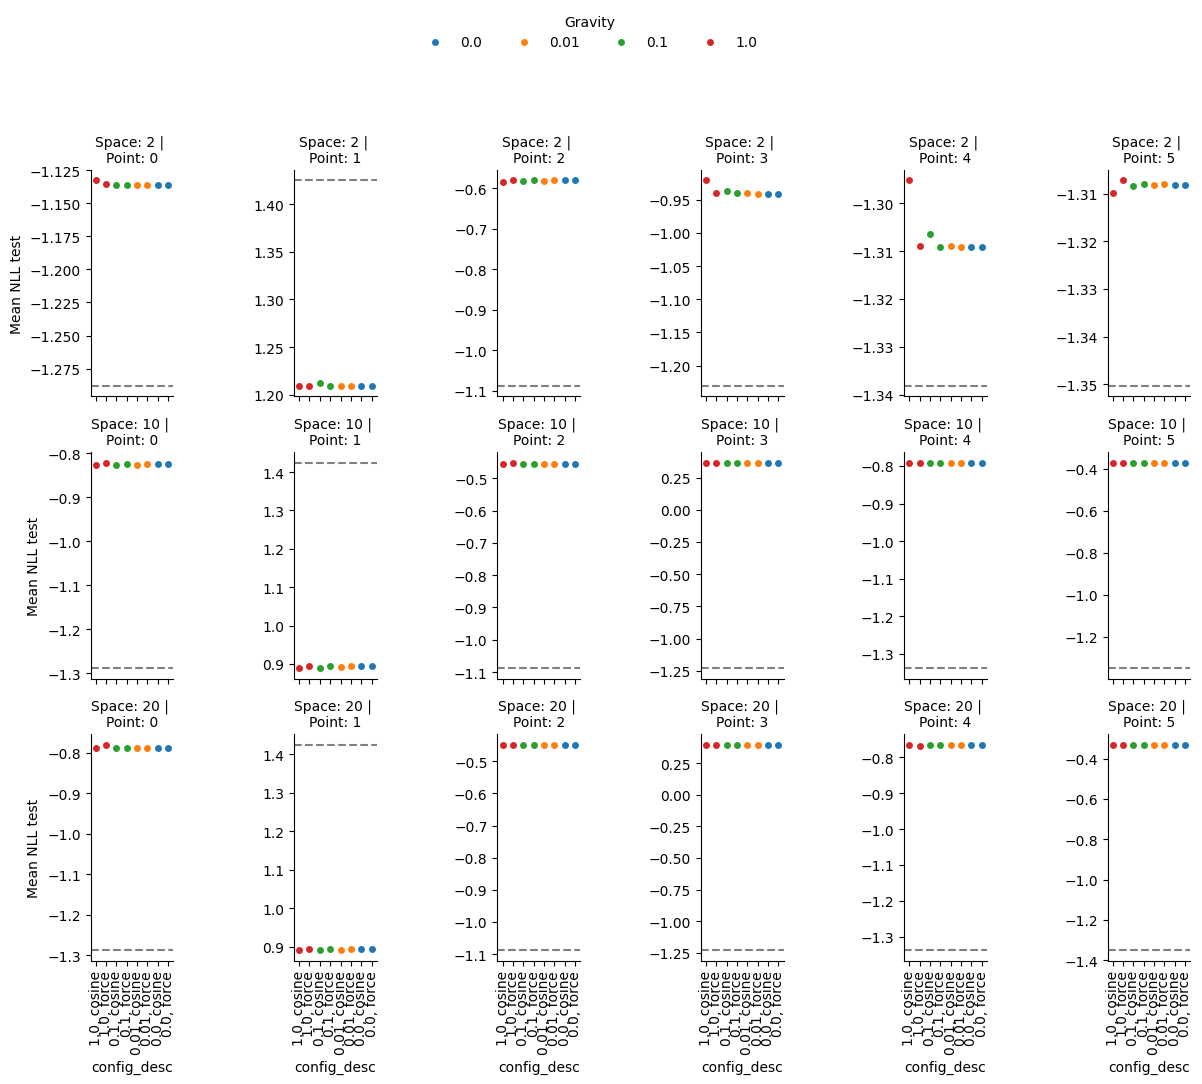

In [49]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_vanilla.copy(deep=True)
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'SeedData', 'Mode'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='nll_test_last', x='config_desc',
                row='SubspaceDim', col='SeedData', kind='strip', hue='Gravity', sharey=False, height=3, aspect=0.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nPoint: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL test")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)
# Add horizontal lines for each ParamsPath column using init_point_performance_test
for ax, params_path in zip(g.axes[0].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[1].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[2].flat, g.col_names):
    ax.axhline(y=init_point_performance_test[params_path], color='gray', linestyle='--', label='init point')

In [50]:
df_vanilla.columns.values

array(['Id', 'SubspaceDim', 'SeedData', 'Jitter', 'Gravity',
       'WeightDecay', 'RemoveInitialPermutation', 'Epochs', 'Lr',
       'EnergyWeakening', 'Regularizer', 'mse_test', 'mse_test_last',
       'mse_val', 'mse_val_last', 'nll_test', 'nll_test_last', 'nll_val',
       'nll_val_last', 'length_best', 'length_last', 'mse_test_min',
       'mse_test_last_min', 'mse_val_min', 'mse_val_last_min',
       'nll_test_min', 'nll_test_last_min', 'nll_val_min',
       'nll_val_last_min', 'cosine_similarity', 'sample_std_best',
       'sample_std_last', 'Mode'], dtype=object)

['Gravity' 'Regularizer']


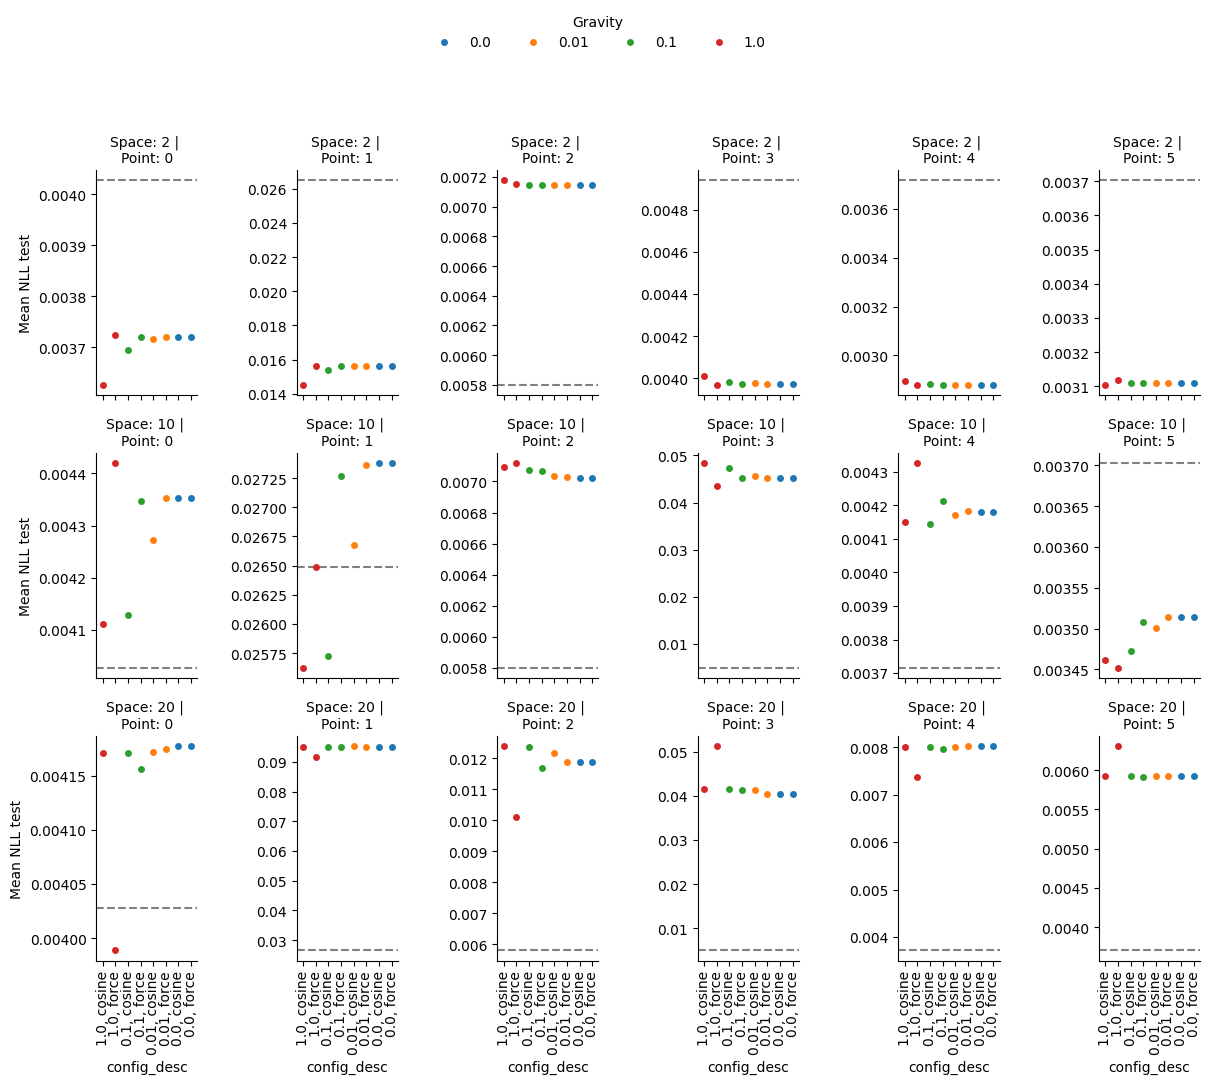

In [56]:
# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_vanilla.copy(deep=True)
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'SeedData', 'Mode'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='mse_test_last_min', x='config_desc',
                row='SubspaceDim', col='SeedData', kind='strip', hue='Gravity', sharey=False, height=3, aspect=0.7, palette='tab10')
g.set_titles(row_template='Space: {row_name}',
             col_template='\nPoint: {col_name}')
g.tight_layout()
g.set_ylabels("Mean NLL test")
# g.set(ylim=(0., 22.96))
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)
# Add horizontal lines for each ParamsPath column using init_point_performance_test
for ax, params_path in zip(g.axes[0].flat, g.col_names):
    ax.axhline(y=init_point_performance_mse_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[1].flat, g.col_names):
    ax.axhline(y=init_point_performance_mse_test[params_path], color='gray', linestyle='--', label='init point')
for ax, params_path in zip(g.axes[2].flat, g.col_names):
    ax.axhline(y=init_point_performance_mse_test[params_path], color='gray', linestyle='--', label='init point')